### Manuscript Name: Evaluating the Impact of Packet Scheduling and Congestion Control Algorithms on MPTCP Performance over Heterogeneous Networks
#### Code Author(s)
* **Dimitris Dimopoulos**
#### Copyright & License
Copyright (c) 2026 Dimitris Dimopoulos. This project is licensed under the GPL 3.0 License.


# Actual Results

In [ ]:
# Jupyter code - To be further split in more granular steps

# %matplotlib widget
# import ipympl
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os
from subprocess import run, Popen, PIPE
from subprocess import CompletedProcess
# import seaborn as sns
import numpy as np
import textwrap


def copy_from_remote(remote_path, local_path):
    target_server_ip = 'xx.xx.xx.xx'        # add your remote file-server's IP
    target_server_port = 'xxxx'             # add your remote file-server's port
    target_server_user = 'username'         # add your remote file-server's username
    rsa_key_path = '/home/mininet/.ssh/id_rsa'  # modify accordingly
    hostKeyCheck = 'StrictHostKeyChecking accept-new'
    target_server = target_server_user + '@' + target_server_ip + ':' + remote_path
    
    result = run(["scp", 
                  '-P', target_server_port,
                  '-o', hostKeyCheck,  
                  '-i', rsa_key_path, 
                  '-r', target_server, 
                  local_path], check=True)
    CompletedProcess.check_returncode(result)


def return_file_w_pattern(dir, pattern):
    found = False
    for file in os.listdir(dir):
        filename = os.path.join(dir, file)
        if os.path.isfile(filename) and pattern in str(filename):
            found = True
            break
    if found:
        return file
    else:
        print("File with requested pattern not found!\n")
        exit()


def sorted_dir_list(dir):
    files = os.listdir(dir)
    sorted_files = sorted(files)
    return sorted_files


# Paths
local_path = "/home/mininet/mininet/mininet_dd/full_suite/analysis"  # VM-specific
remote_merge_path = "/home/ubuntu/code_backup/mininet_dd/full_suite/analysis/merge_results/"

# cc_list = ['olia', 'lia', 'balia', 'wvegas', 'cubic', 'bbr', 'c-mpbbr']
cc_list = ['c-mpbbr']


# Fetch files from remote
for cc in cc_list:
    target_path = os.path.join(remote_merge_path, cc)  # remote_path + cc + '/'
    # copy_from_remote(target_path, local_path)  # fetch directory from remote server
    cc_filepath = os.path.join(local_path, cc)
    for outer_scenario in os.listdir(cc_filepath):  # i.e. homogen, mild, ..
        outer_scenario_path = os.path.join(cc_filepath, outer_scenario)
        subscen_num = len([fname for fname in os.listdir(outer_scenario_path) if os.path.isdir(os.path.join(outer_scenario_path, fname))])  #  # of e1, e2, .. -> will be the figure's column size - i.e. homogen/e1, e2, e3..

        # Customize figure size and fontsize based on the number of subscenarios
        if subscen_num > 6:
            fig_horiz_dimen = 18
            fig_vert_dimen = 9
            title_font_size = 10
        else:
            fig_horiz_dimen = 10
            fig_vert_dimen = 7
            title_font_size = 9

        # Create figure and subplots
        fig, axes = plt.subplots(4, subscen_num, figsize=(fig_horiz_dimen, fig_vert_dimen), sharex=True, sharey=False, layout='constrained')  # sharey='row' // gridspec_kw={'height_ratios': [4, 7]}  // layout='constrained'
        axes[0][0].set_ylabel('Goodput\n'+r'$\mathit{Mbit/s}$', multialignment='center', fontsize='medium')
        axes[1][0].set_ylabel('SRTT\n'+r'$\mathit{ms}$', multialignment='center', fontsize='medium')
        axes[2][0].set_ylabel('Out-of-Order\nqueue size\n'+r'$\mathit{KiB}$', multialignment='center', fontsize='medium')
        axes[3][0].set_ylabel('# of retransmissions\n', multialignment='center', fontsize='medium')
        fig.suptitle(str(cc) + ' - ' + str(outer_scenario))

        # iter = -1
        subscen_files = []
        subscen_files = sorted_dir_list(outer_scenario_path)
        for iter, subscen in enumerate(subscen_files):
            # iter += 1
            subscen_path = os.path.join(outer_scenario_path, subscen)

            #################
            #--  Goodput  --#
            #################
            gp_fname = return_file_w_pattern(subscen_path, 'goodput')
            gp_csv = os.path.join(subscen_path, gp_fname)
            gp_df = pd.read_csv(gp_csv, skipinitialspace=True)

            # Identify categories -- x-ticks
            unique_categories = gp_df['scheduler'].unique().tolist()
            print("\n Unique Categories: ", unique_categories)
            # x_ticks = np.arange(len(unique_categories))  # Central positions for categories

            print(f"-------------#GP: grouped_gp_df----- {subscen} -------:\n", )     # DF constructred OK -----> REMOVE block
            grouped_gp_df = gp_df.groupby('scheduler')[['sf1_gp', 'sf2_gp']]
            for key, item in grouped_gp_df:
                print(grouped_gp_df.get_group(key),"\n\n")

            grouped = gp_df.groupby('scheduler')[['sf1_gp', 'sf2_gp']].mean()  # mean calculation
            # print("\n\n Grouped mean:\n\n", grouped)
            grouped = grouped.reindex(unique_categories)
            print("\n\n Grouped mean -- Reindexed:\n\n", grouped)

            std = gp_df.groupby('scheduler')[['sf1_gp', 'sf2_gp']].std()  # std calculation -- @ SOS: shoule be 'ddof=0' -- default is 'ddof=1', so 4/5 executions counted in 'std' calculation
            # print("\n\n Grouped std:\n\n", std)
            std = std.reindex(unique_categories)
            print("\n\n Grouped std -- Reindexed:\n\n", std)

            # Goodput bar plot
            error_kw=dict(lw=0.7, capsize=0)
            axes[0][iter].bar(grouped.index, grouped['sf1_gp'], yerr=std['sf1_gp'], label='sf1_gp', width=0.5, error_kw=error_kw, color='#d1b26f')
            axes[0][iter].bar(grouped.index, grouped['sf2_gp'], bottom=grouped['sf1_gp'], yerr=std['sf2_gp'], label='sf2_gp', width=0.5, error_kw=error_kw, color='#029386')
            axes[0][iter].set_title(str(subscen), fontsize=title_font_size)
            axes[0][iter].grid(axis='y', linestyle='--', alpha=0.2)
            axes[0][iter].set_xticks([])  # Remove x-tick labels
            axes[0][iter].set_xticklabels([])
            axes[0][iter].set_ylim(bottom=0, top=220)

            ##############
            #--  SRTT  --#
            ##############
            #---------------------------------------------------------------#
            #             Boxplots - Matplotlib                             #
            #      Q1-1.5IQR   Q1  median   Q3   Q3+1.5IQR                  #
            #                   |-----:-----|                               #
            #   o      |--------|     :     |--------|    o  o              #
            #                   |-----:-----|                               #
            # flier             <----------->            fliers             #
            #                        IQR                                    #
            #---------------------------------------------------------------#

            sf1_srtt_fname = return_file_w_pattern(subscen_path, 'sf1_srtt')
            sf1_srtt_csv = os.path.join(subscen_path, sf1_srtt_fname)
            sf1_srtt_df = pd.read_csv(sf1_srtt_csv, skipinitialspace=True)

            sf2_srtt_fname = return_file_w_pattern(subscen_path, 'sf2_srtt')
            sf2_srtt_csv = os.path.join(subscen_path, sf2_srtt_fname)
            sf2_srtt_df = pd.read_csv(sf2_srtt_csv, skipinitialspace=True)

            # Define positions for boxplots
            unique_categories = sf1_srtt_df['scheduler'].unique().tolist()      # check 'sorted()', if needed
            print("\n Unique Categories: ", unique_categories)
            x_ticks = np.arange(len(unique_categories))  # Central positions for categories

            positions1 = x_ticks - 0.2  # Offset for value1 boxplots
            positions2 = x_ticks + 0.2  # Offset for value2 boxplots

            # SRTT Boxplots on the second row of the figure
            axes[1][iter].boxplot(
                [sf1_srtt_df[sf1_srtt_df["scheduler"] == cat]["sf1_srtt"] for cat in unique_categories],
                positions=positions1, widths=0.3, patch_artist=True, showfliers=False, notch=False, showmeans=False, meanline=False,        # "notch vs meanline": https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html
                boxprops=dict(facecolor='#d1b26f', color='black')  # color='#d1b26f'
            )
            axes[1][iter].boxplot(
                [sf2_srtt_df[sf2_srtt_df["scheduler"] == cat]["sf2_srtt"] for cat in unique_categories],
                positions=positions2, widths=0.3, patch_artist=True, showfliers=False, notch=False, showmeans=False, meanline=False,
                boxprops=dict(facecolor='#029386', color='black')  # color='#029386'
            )

            # Customize the second subplot
            # axes[1].set_title("Boxplots of Value1 and Value2")
            axes[1][iter].set_xticks([])  # Remove x-tick labels
            axes[1][iter].set_xticklabels([])
            axes[1][iter].set_ylim(bottom=0)  # changes axes values to floating!
            axes[1][iter].grid(axis='y', linestyle='--', alpha=0.2)

            ###################
            #--  OFO queue  --#
            ###################
            ofo_fname = return_file_w_pattern(subscen_path, 'ofo')
            ofo_csv = os.path.join(subscen_path, ofo_fname)
            ofo_df = pd.read_csv(ofo_csv, skipinitialspace=True)

            # OFO Boxplots on the third row of the figure
            axes[2][iter].boxplot(
                [ofo_df[ofo_df["scheduler"] == cat]["ofo"] for cat in unique_categories], positions=x_ticks,    # positions=x_ticks -> this is necessary to reset the position of the x_ticks implicitly modified previously
                widths=0.3, patch_artist=True, showfliers=False, notch=False, showmeans=False, meanline=False,  # "notch vs meanline": https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html
                boxprops=dict(facecolor='#d0fefe', color='black')  # color='#d1b26f' // facecolor='#d0fefe'
            )

            # axes[2][iter].set_xlim([-0.15, len(unique_categories)-0.15])
            axes[2][iter].set_xticks([])  #----> x_ticks
            axes[2][iter].set_xticklabels([])  #---> unique_categories
            axes[2][iter].set_ylim(bottom=0)  # changes axes values to floating!
            axes[2][iter].grid(axis='y', linestyle='--', alpha=0.2)

            #########################
            #--  Retransmissions  --#
            #########################
            print(f"-------------#Retransm: grouped_retransm_df----- {subscen} -------:\n", )     # DF constructred OK
            grouped_retr = gp_df.groupby('scheduler')[['sf1_retransm', 'sf2_retransm']]
            for key, item in grouped_retr:
                print(grouped_retr.get_group(key),"\n\n")

            # print("\n\n")
            grouped_retransm = gp_df.groupby('scheduler')[['sf1_retransm', 'sf2_retransm']].mean()  # retransmissions' mean calculation -- !!!!@@@@@@  possible issue here!
            print("\n\n Grouped_retransmissions' mean:\n\n", grouped_retransm)
            grouped_retransm = grouped_retransm.reindex(unique_categories)
            print("\n\n Grouped_retransm mean -- Reindexed:\n\n", grouped_retransm)
            
            std_retransm = gp_df.groupby('scheduler')[['sf1_retransm', 'sf2_retransm']].std()  # retransmissions' std calculation
            print("\n\n Grouped retransmissions' std:\n\n", std_retransm)
            std_retransm = std_retransm.reindex(unique_categories)
            print("\n\n Grouped retransmissions' std -- Reindexed:\n\n", std_retransm)

            # Retransmissions' stacked bar plot
            error_kw=dict(lw=0.7, capsize=0)
            axes[3][iter].bar(grouped_retransm.index, grouped_retransm['sf1_retransm'], yerr=std_retransm['sf1_retransm'], label='sf1_retransm', width=0.5, error_kw=error_kw, color='#d1b26f')
            axes[3][iter].bar(grouped_retransm.index, grouped_retransm['sf2_retransm'], bottom=grouped_retransm['sf1_retransm'], yerr=std_retransm['sf2_retransm'], label='sf2_retransm', width=0.5, error_kw=error_kw, color='#029386')

            axes[3][iter].grid(axis='y', linestyle='--', alpha=0.2)
            axes[3][iter].set_xticks(x_ticks)
            axes[3][iter].set_xticklabels(unique_categories)
            axes[3][iter].set_ylim(bottom=0)  # check without "top=600" for individual y axis units and respectively individual bar expansion

            axes[3][iter].tick_params(axis='x', labelsize=title_font_size, labelrotation=90)  # labelsize=9 -- move below in retransm part!



        # Adjust layout
        fig.align_labels()  # same as fig.align_xlabels(); fig.align_ylabels()
        fig.align_titles()
        # plt.tight_layout()

        # Get unique legend handles and labels
        handles, labels = fig.axes[0].get_legend_handles_labels()
        unique_labels = dict(zip(labels, handles))  # Remove duplicates by converting to dictionary
        
        # Rename labels
        renamed_labels = {
            "sf1_gp": "Subflow 1",
            "sf2_gp": "Subflow 2"
        }

        # Create a single legend outside the subplots with renamed labels
        fig.legend(unique_labels.values(), [renamed_labels[i] for i in unique_labels.keys()], loc='lower left', frameon=True, fontsize = 'small')     # ncols=2
        # plt.tight_layout(rect=[0, 0, 1, 0.95])  # Adjust layout to fit the legend
        plt.show()



# # # Add legend for the boxplots
# # custom_legend = [
# #     plt.Line2D([0], [0], color='lightblue', lw=4, label='Value1'),
# #     plt.Line2D([0], [0], color='lightgreen', lw=4, label='Value2')
# # ]
# # axes[1].legend(handles=custom_legend, loc='upper left')

# # Adjust layout
# plt.tight_layout()
# plt.show()




# Cross-CC

In [ ]:
# Jupyter code - To be further split in more granular steps

# %matplotlib widget
# import ipympl
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os
from subprocess import run, Popen, PIPE
from subprocess import CompletedProcess
# import seaborn as sns
import numpy as np
import textwrap


def copy_from_remote(remote_path, local_path):
    target_server_ip = 'xx.xx.xx.xx'        # add your remote file-server's IP
    target_server_port = 'xxxx'             # add your remote file-server's port
    target_server_user = 'username'         # add your remote file-server's username
    rsa_key_path = '/home/mininet/.ssh/id_rsa'  # modify accordingly
    hostKeyCheck = 'StrictHostKeyChecking accept-new'
    target_server = target_server_user + '@' + target_server_ip + ':' + remote_path
    
    result = run(["scp", 
                  '-P', target_server_port,
                  '-o', hostKeyCheck,  
                  '-i', rsa_key_path, 
                  '-r', target_server, 
                  local_path], check=True)
    CompletedProcess.check_returncode(result)


def return_file_w_pattern(dir, pattern):
    found = False
    for file in os.listdir(dir):
        filename = os.path.join(dir, file)
        if os.path.isfile(filename) and pattern in str(filename):
            found = True
            break
    if found:
        return file
    else:
        print("File with requested pattern not found!\n")
        exit()


def sorted_dir_list(dir):
    files = os.listdir(dir)
    sorted_files = sorted(files)
    return sorted_files


def extract_cc_from_path(pathname):
    for cc in cc_list:
        cc_pattern_in_path = '/' + str(cc)
        if str(pathname).find(cc_pattern_in_path) != -1:
            return cc


# Paths
local_path = "/home/mininet/mininet/mininet_dd/full_suite/analysis"  # VM-specific
remote_merge_path = "/home/ubuntu/code_backup/mininet_dd/full_suite/analysis/merge_results/"

cc_list = ['olia', 'lia', 'balia', 'wvegas', 'cubic', 'bbr', 'c-mpbbr']
# cc_list = ['wvegas', 'lia']

# Matplotlib figure size constants -- fixed number of columns in Cross-CC scenarios
fig_horiz_dimen = 18
fig_vert_dimen = 9
title_font_size = 10

checked_cc = []
cross_cc_subscen = []

# Fetch files from remote
for cc in cc_list:
    target_path = os.path.join(remote_merge_path, cc)  # remote_path + cc + '/'
    # copy_from_remote(target_path, local_path)  # fetch directory from remote server

for cc in cc_list:
    # cc = cc_list[0]
    cc_filepath = os.path.join(local_path, cc)
    for outer_scenario in os.listdir(cc_filepath):  # i.e. homogen, mild, ..
        outer_scenario_path = os.path.join(cc_filepath, outer_scenario)

        subscen_files = []
        subscen_files = sorted_dir_list(outer_scenario_path)
        for iter, subscen in enumerate(subscen_files):
            subscen_num = len(cc_list)
            # Create figure and subplots
            fig, axes = plt.subplots(4, subscen_num, figsize=(fig_horiz_dimen, fig_vert_dimen), sharex=True, sharey=False, layout='constrained')  # sharey='row' // gridspec_kw={'height_ratios': [4, 7]}  // layout='constrained' // dpi=500
            axes[0][0].set_ylabel('Goodput\n'+r'$\mathit{Mbit/s}$', multialignment='center', fontsize='medium')
            axes[1][0].set_ylabel('SRTT\n'+r'$\mathit{ms}$', multialignment='center', fontsize='medium')
            axes[2][0].set_ylabel('Out-of-Order\nqueue size\n'+r'$\mathit{KiB}$', multialignment='center', fontsize='medium')
            axes[3][0].set_ylabel('# of retransmissions\n', multialignment='center', fontsize='medium')
            fig.suptitle(str(subscen))

            # print("Out cc list:",cc_list)
            for inner_cc in cc_list:
                # print("In cc list:",cc_list)
                # print("Inner_cc:", inner_cc)
                if inner_cc not in checked_cc:
                    checked_cc.append(inner_cc)
                    inner_scen_pattern = str(outer_scenario) + '/' + str(subscen)
                    inner_cc_filepath = os.path.join(local_path, inner_cc)
                    full_inner_cc_subscen_path = os.path.join(inner_cc_filepath, inner_scen_pattern)
                    cross_cc_subscen.append(full_inner_cc_subscen_path)   # each time, keep a list with the full paths of all identical subscenarios (belonging to the same outer scenario: e.g. 'homogen') of all CCs, i.e.: 'e1_hom' from 'balia', 'lia', 'olia', ..
                    # print("----> Inner scen full path: ", full_inner_cc_subscen_path)
            # print("list:", cross_cc_subscen)
            for inner_iter in range(len(cross_cc_subscen)):
                subscen_path = str(cross_cc_subscen[inner_iter])
                cc_in_pathname = extract_cc_from_path(subscen_path)

                #################
                #--  Goodput  --#
                #################
                gp_fname = return_file_w_pattern(subscen_path, 'goodput')
                print("GP FNAME:", gp_fname) # <--------
                gp_csv = os.path.join(subscen_path, gp_fname)
                gp_df = pd.read_csv(gp_csv, skipinitialspace=True)

                unique_categories = gp_df['scheduler'].unique().tolist()
                print("\n Unique Categories: ", unique_categories)

                grouped = gp_df.groupby('scheduler')[['sf1_gp', 'sf2_gp']].mean()  # mean calculation
                print("\n\n Grouped mean:\n\n", grouped)
                grouped = grouped.reindex(unique_categories)
                print("\n\n Grouped mean -- Reindexed:\n\n", grouped)
                
                std = gp_df.groupby('scheduler')[['sf1_gp', 'sf2_gp']].std()  # std calculation
                print("\n\n Grouped std:\n\n", std)
                std = std.reindex(unique_categories)
                print("\n\n Grouped std -- Reindexed:\n\n", std)

                # Goodput bar plot
                error_kw=dict(lw=0.7, capsize=0)
                axes[0][inner_iter].bar(grouped.index, grouped['sf1_gp'], yerr=std['sf1_gp'], label='sf1_gp', width=0.5, error_kw=error_kw, color='#d1b26f')
                axes[0][inner_iter].bar(grouped.index, grouped['sf2_gp'], bottom=grouped['sf1_gp'], yerr=std['sf2_gp'], label='sf2_gp', width=0.5, error_kw=error_kw, color='#029386')
                axes[0][inner_iter].set_title(str(cc_in_pathname), fontsize=title_font_size)
                axes[0][inner_iter].grid(axis='y', linestyle='--', alpha=0.2)
                axes[0][inner_iter].set_xticks([])  # Remove x-tick labels
                axes[0][inner_iter].set_xticklabels([])
                axes[0][inner_iter].set_ylim(bottom=0, top=220)

                ##############
                #--  SRTT  --#
                ##############
                #---------------------------------------------------------------#
                #             Boxplots - Matplotlib                             #
                #      Q1-1.5IQR   Q1  median   Q3   Q3+1.5IQR                  #
                #                   |-----:-----|                               #
                #   o      |--------|     :     |--------|    o  o              #
                #                   |-----:-----|                               #
                # flier             <----------->            fliers             #
                #                        IQR                                    #
                #---------------------------------------------------------------#

                sf1_srtt_fname = return_file_w_pattern(subscen_path, 'sf1_srtt')
                sf1_srtt_csv = os.path.join(subscen_path, sf1_srtt_fname)
                sf1_srtt_df = pd.read_csv(sf1_srtt_csv, skipinitialspace=True)

                sf2_srtt_fname = return_file_w_pattern(subscen_path, 'sf2_srtt')
                sf2_srtt_csv = os.path.join(subscen_path, sf2_srtt_fname)
                sf2_srtt_df = pd.read_csv(sf2_srtt_csv, skipinitialspace=True)

                # Define positions for boxplots
                unique_categories = sf1_srtt_df['scheduler'].unique().tolist()
                print("\n Unique Categories: ", unique_categories)
                x_ticks = np.arange(len(unique_categories))  # Central positions for categories

                positions1 = x_ticks - 0.2  # Offset for value1 boxplots
                positions2 = x_ticks + 0.2  # Offset for value2 boxplots

                # SRTT Boxplots on the second row of the figure
                axes[1][inner_iter].boxplot(
                    [sf1_srtt_df[sf1_srtt_df["scheduler"] == cat]["sf1_srtt"] for cat in unique_categories],
                    positions=positions1, widths=0.3, patch_artist=True, showfliers=False, notch=False, showmeans=False, meanline=False,        # "notch vs meanline": https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html
                    boxprops=dict(facecolor='#d1b26f', color='black')  # color='#d1b26f'
                )
                axes[1][inner_iter].boxplot(
                    [sf2_srtt_df[sf2_srtt_df["scheduler"] == cat]["sf2_srtt"] for cat in unique_categories],
                    positions=positions2, widths=0.3, patch_artist=True, showfliers=False, notch=False, showmeans=False, meanline=False,
                    boxprops=dict(facecolor='#029386', color='black')  # color='#029386'
                )

                # Customize the second subplot
                # axes[1].set_title("Boxplots of Value1 and Value2")
                axes[1][inner_iter].set_xticks([])  # Remove x-tick labels
                axes[1][inner_iter].set_xticklabels([])
                axes[1][inner_iter].set_ylim(bottom=0)  # changes axes values to floating!
                axes[1][inner_iter].grid(axis='y', linestyle='--', alpha=0.2)

                ###################
                #--  OFO queue  --#
                ###################
                ofo_fname = return_file_w_pattern(subscen_path, 'ofo')
                ofo_csv = os.path.join(subscen_path, ofo_fname)
                ofo_df = pd.read_csv(ofo_csv, skipinitialspace=True)

                # OFO Boxplots on the third row of the figure
                axes[2][inner_iter].boxplot(
                    [ofo_df[ofo_df["scheduler"] == cat]["ofo"] for cat in unique_categories], positions=x_ticks,    # positions=x_ticks -> this is necessary to reset the position of the x_ticks implicitly modified previously
                    widths=0.3, patch_artist=True, showfliers=False, notch=False, showmeans=False, meanline=False,  # "notch vs meanline": https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html
                    boxprops=dict(facecolor='#d0fefe', color='black')  # color='#d1b26f' // facecolor='#d0fefe'
                )

                # axes[2][inner_iter].set_xlim([-0.15, len(unique_categories)-0.15])
                axes[2][inner_iter].set_xticks([])  #----> x_ticks
                axes[2][inner_iter].set_xticklabels([])  #---> unique_categories
                axes[2][inner_iter].set_ylim(bottom=0)  # changes axes values to floating!
                axes[2][inner_iter].grid(axis='y', linestyle='--', alpha=0.2)

                #########################
                #--  Retransmissions  --#
                #########################
                grouped_retransm = gp_df.groupby('scheduler')[['sf1_retransm', 'sf2_retransm']].mean()  # retransmissions' mean calculation
                print("\n\n Grouped_retransmissions' mean:\n\n", grouped_retransm)
                grouped_retransm = grouped_retransm.reindex(unique_categories)
                print("\n\n Grouped_retransm mean -- Reindexed:\n\n", grouped_retransm)
                
                std_retransm = gp_df.groupby('scheduler')[['sf1_retransm', 'sf2_retransm']].std()  # retransmissions' std calculation
                print("\n\n Grouped retransmissions' std:\n\n", std_retransm)
                std_retransm = std_retransm.reindex(unique_categories)
                print("\n\n Grouped retransmissions' std -- Reindexed:\n\n", std_retransm)

                # Retransmissions' stacked bar plot
                error_kw=dict(lw=0.7, capsize=0)
                axes[3][inner_iter].bar(grouped_retransm.index, grouped_retransm['sf1_retransm'], yerr=std_retransm['sf1_retransm'], label='sf1_retransm', width=0.5, error_kw=error_kw, color='#d1b26f')
                axes[3][inner_iter].bar(grouped_retransm.index, grouped_retransm['sf2_retransm'], bottom=grouped_retransm['sf1_retransm'], yerr=std_retransm['sf2_retransm'], label='sf2_retransm', width=0.5, error_kw=error_kw, color='#029386')

                axes[3][inner_iter].grid(axis='y', linestyle='--', alpha=0.2)
                axes[3][inner_iter].set_xticks(x_ticks)
                axes[3][inner_iter].set_xticklabels(unique_categories)
                axes[3][inner_iter].set_ylim(bottom=0)  # check without "top=600" for individual y axis units and respectively individual bar expansion

                axes[3][inner_iter].tick_params(axis='x', labelsize=title_font_size, labelrotation=90)  # labelsize=9 -- move below in retransm part!

            # Adjust layout
            fig.align_labels()  # same as fig.align_xlabels(); fig.align_ylabels()
            fig.align_titles()
            # plt.tight_layout()
            # fig.legend(loc='outside lower left')
            
            # Get unique legend handles and labels
            handles, labels = fig.axes[0].get_legend_handles_labels()
            unique_labels = dict(zip(labels, handles))  # Remove duplicates by converting to dictionary
            
            # Rename labels
            renamed_labels = {
                "sf1_gp": "Subflow 1",
                "sf2_gp": "Subflow 2"
            }

            # Create a single legend outside the subplots with renamed labels
            fig.legend(unique_labels.values(), [renamed_labels[i] for i in unique_labels.keys()], loc='lower left', frameon=True, fontsize = 'small')     # ncols=2
            # plt.tight_layout(rect=[0, 0, 1, 0.95])  # Adjust layout to fit the legend

            plt.show()

            checked_cc = []
            cross_cc_subscen = []
            # break
        # break
    break


Calculation of each Scheduler's Avg. Goodput per CCA

In [ ]:
# Jupyter code - To be further split in more granular steps

# %matplotlib widget
# import ipympl
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os
from subprocess import run, Popen, PIPE
from subprocess import CompletedProcess
# import seaborn as sns
import numpy as np
import textwrap
from shutil import move, rmtree
import pwd, grp


def copy_from_remote(remote_path, local_path):
    target_server_ip = 'xx.xx.xx.xx'        # add your remote file-server's IP
    target_server_port = 'xxxx'             # add your remote file-server's port
    target_server_user = 'username'         # add your remote file-server's username
    rsa_key_path = '/home/mininet/.ssh/id_rsa'  # modify accordingly
    hostKeyCheck = 'StrictHostKeyChecking accept-new'
    target_server = target_server_user + '@' + target_server_ip + ':' + remote_path
    
    result = run(["scp", 
                  '-P', target_server_port,
                  '-o', hostKeyCheck,  
                  '-i', rsa_key_path, 
                  '-r', target_server, 
                  local_path], check=True)
    CompletedProcess.check_returncode(result)


def create_dir(dir_path):
    # df = pd.read_csv(filename)
    # dir_name = df.iloc[i]['id'] + '_' + df.iloc[i]['subdir_name']
    # dir_path = "/home/xx/mininet/mininet_dd/full_suite/iperf/iperf_results/" + dir_name
    if not os.path.isdir(dir_path):
        os.makedirs(dir_path)
        uid = pwd.getpwnam("mininet").pw_uid
        gid = grp.getgrnam("mininet").gr_gid
        os.chown(dir_path, uid, gid)


def delete_directory(dir_path):
    if os.path.isdir(dir_path):
        rmtree(dir_path)
    else:
        raise Exception("Path either points to file or does not exist!")


def return_file_w_pattern(dir, pattern):
    found = False
    for file in os.listdir(dir):
        filename = os.path.join(dir, file)
        if os.path.isfile(filename) and pattern in str(filename):
            found = True
            break
    if found:
        return file
    else:
        print("File with requested pattern not found!\n")
        exit()


def create_csv_file(dirpath, id, target):
    csv_name = f"{id}_{target}.csv"
    csv_full_name = os.path.join(dirpath, csv_name)
    with open(csv_full_name, 'w', encoding='utf-8') as f:
        if target == 'goodput':
            f.write("scenario_family,subscen_id,avg_aggr_gp\n")
        elif target == 'score':
            f.write("scenario_family,score\n")
    return csv_full_name


def calculate_average_goodput(gp_file_full_path, scheduler):
    with open(gp_file_full_path, 'r', encoding='utf-8') as f:
        lines = f.readlines()
        i = 0
        gp_sum = 0.0
        avg_gp = 0.0
        for line in lines:
            if str(line).startswith(scheduler) is True:
                gp_sample = float(str(line).split(",")[1].lstrip())
                # print(f"{scheduler} -> GP_sample = {str(gp_sample)}")
                gp_sum += float(str("%.3f" % float(gp_sample)))
                i+=1
        if i == 5:
            # print(f"{scheduler} -> GP_sum = {str(gp_sum)}")
            avg_gp = float(str("%.3f" % float(gp_sum / 5)))
            # print(f"-> Avg goodput: {str(avg_gp)}")
        else:
            print(f"Less than five goodput entries included in the original merged .csv file for scheduler {scheduler}.")
            exit()
    return str(avg_gp)


def append_avg_gp(csv_full_path, scenario_family, subscenario_id, avg_aggr_gp):
    with open(csv_full_path, 'a', encoding='utf-8') as f:
        f.write("%s,%s,%s\n" %(scenario_family, subscenario_id, avg_aggr_gp))


def calculate_sched_score(gp_file_full_path, score_file_path, id):
    with open(gp_file_full_path, 'r', encoding='utf-8') as gp_f:
        lines = gp_f.readlines()
        i = 0
        gp_sum = 0.0
        score = 0.0
        for line in lines:
            if str(line).startswith(id) is True:
                gp_sample = float(str(line).split(",")[2].lstrip())
                gp_sum += float(str("%.3f" % float(gp_sample)))
                i+=1
                # print(f"Here, line: {line}")
        if ((id == 'homogen' or id == 'mix_het') and (i!=4)) or ((id == 'int_het' or id == 'mild_het' or id == 'v_int_het') and (i!=7)):
            # print(f"Subscenario: {id}, i = {i}, score_fp = {score_file_path}")
            print(f"Subscenario entries do not match the expected number.")
            exit()
        score = float(str("%.2f" % float(gp_sum / float(i * 200))))
    with open(score_file_path, 'a', encoding='utf-8') as sc_f:
        sc_f.write("%s,%s\n" %(id, str(score)))


def calculate_cc_score(sched_list, score_parent_dir, subscenario, cca_score_full_path):
    i = 0
    sc_sum = 0.0
    cc_score = 0.0
    for sched in sched_list:
        sched_sc_f_pattern = str(sched) + str("_score")
        sched_sc_file = return_file_w_pattern(score_parent_dir, sched_sc_f_pattern)
        sched_score_path = os.path.join(score_parent_dir, sched_sc_file)
        with open(sched_score_path, 'r', encoding='utf-8') as sc_f:
            lines = sc_f.readlines()
            for line in lines:
                if str(line).startswith(subscenario) is True:
                    sc_sample = float(str(line).split(",")[1].lstrip())
                    sc_sum += float(str("%.2f" % float(sc_sample)))
                    i+=1
    if(i!=5):
        print("There is an error: the number of schedulers should be 5 (minRTT, BLEST, ECF, RR, LLHD).\n")
        exit()
    cc_score = float(str("%.2f" % float(sc_sum / i)))
    with open(cca_score_full_path, 'a', encoding='utf-8') as cca_sc_f:
        cca_sc_f.write("%s,%s\n" %(subscenario, str(cc_score)))


# Paths
local_path = "/home/mininet/mininet/mininet_dd/full_suite/analysis/"  # VM-specific
remote_merge_path = "/home/ubuntu/code_backup/mininet_dd/full_suite/analysis/merge_results/"

cc_list = ['olia', 'lia', 'balia', 'wvegas', 'cubic', 'bbr', 'c-mpbbr']
# cc_list = ['bbr']
sched_list = ['minRTT', 'BLEST', 'ECF', 'RR', 'LLHD']
scen_list = ['homogen', 'int_het', 'mild_het', 'mix_het', 'v_int_het']

# create 'final_assessment' dir
assess_dir_name = 'final_assessment'
assess_filepath = os.path.join(local_path, assess_dir_name)
create_dir(assess_filepath)

# Calculate the average goodput achieved by each scheduler in each sub-scenario (e.g., e1, e2, ..) over the 5 identical runs  --> append the results to a per-scheduler .csv file under each CCA assessments' directory
for cc in cc_list:
    assess_cc_dir_path = os.path.join(assess_filepath, cc)
    create_dir(assess_cc_dir_path)
    target_path = os.path.join(remote_merge_path, cc)  # remote_path + cc + '/'
    # copy_from_remote(target_path, local_path)  # fetch directory from remote server
    cc_filepath = os.path.join(local_path, cc)
    for sched in sched_list:
        sched_csv_name = create_csv_file(assess_cc_dir_path, sched, 'goodput') # create an assessments' .csv file per scheduler within parent cc dir
        sched_csv_full_name = os.path.join(assess_cc_dir_path, sched_csv_name)  # scheduler .csv full path
        for outer_scenario in sorted(os.listdir(cc_filepath)):  # i.e. homogen, mild, ..
            outer_scenario_path = os.path.join(cc_filepath, outer_scenario)
            for scenario in sorted(os.listdir(outer_scenario_path)):  # i.e. scenario = 'e1_xyz'
                scenario_path = os.path.join(outer_scenario_path, scenario)
                gp_file = return_file_w_pattern(scenario_path, 'goodput')
                gp_file_full_path = os.path.join(scenario_path, gp_file)
                # print(f"Scenario_family: {outer_scenario} , Sub-scenario: {scenario}  -----------")
                avg_aggr_gp = calculate_average_goodput(gp_file_full_path, sched)
                append_avg_gp(sched_csv_full_name, outer_scenario, scenario, avg_aggr_gp)

# Calculate a score for each Scheduler and each CCA in each scenario family -- 
# - Sched score = Sum_avg_GP (aggregate GP of all subscenarios of single scenario_family) / (#_subscenarios * theoretical_max)
# - CCA score = schedulers' normalized aggregate goodput in each scenario family
# CCA_score e[0, 1) = Sum_avg_GP (of all schedulers in each scenario family) / (num_of_sced * theoritical_max * #_subscenarios)
# CCA_score e[0, 1) = Sum_avg_GP / (5 * 200 * #_subscenarios)
# CCA cross-scenario score:  overall_CCA_score e[0, 1) = Sum_of_ScenarioFamily_scores / num_of_ScenarioFamilies 

for cc in cc_list:
    assess_cc_dir_path = os.path.join(assess_filepath, cc)
    # calculate each scheduler's score in each scenario family - single score file per scheduler (per CCA)
    for sched in sched_list:
        sched_score_csv_name = create_csv_file(assess_cc_dir_path, sched, 'score') # create a score .csv file per scheduler within parent cc dir
        sched_score_csv_full_path = os.path.join(assess_cc_dir_path, sched_score_csv_name)
        sched_gp_f_pattern = str(sched) + str("_goodput")
        sched_gp_file = return_file_w_pattern(assess_cc_dir_path, sched_gp_f_pattern)
        sched_gp_file_full_path = os.path.join(assess_cc_dir_path, sched_gp_file)
        for scen in scen_list:
            calculate_sched_score(sched_gp_file_full_path, sched_score_csv_full_path, scen)
    # calculate each CCA's score in each scenario family -- CCA_scen_fam_score = Sum(Sched_scen_fam_score) / #_of_sched
    cca_score_csv_name = create_csv_file(assess_cc_dir_path, cc, 'score') # create a score .csv file per CCA within parent cc dir
    cca_score_csv_full_path = os.path.join(assess_cc_dir_path, cca_score_csv_name)
    for scen in scen_list:
        calculate_cc_score(sched_list, assess_cc_dir_path, scen, cca_score_csv_full_path)

# delete_directory(assess_filepath)



CCAs' assessment per scenario family - Plotting

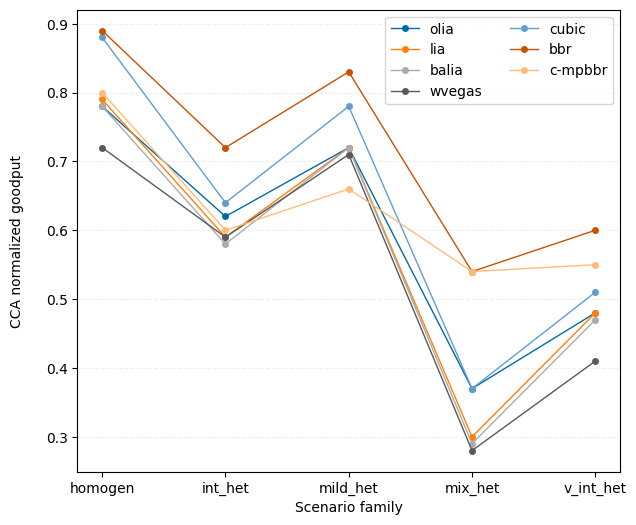

In [ ]:
# %matplotlib widget
# import ipympl
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os


def return_file_w_pattern(dir, pattern):
    found = False
    for file in os.listdir(dir):
        filename = os.path.join(dir, file)
        if os.path.isfile(filename) and pattern in str(filename):
            found = True
            break
    if found:
        return file
    else:
        print("File with requested pattern not found!\n")
        exit()


# Paths
local_path = "/home/mininet/mininet/mininet_dd/full_suite/analysis/"  # VM-specific
remote_merge_path = "/home/ubuntu/code_backup/mininet_dd/full_suite/analysis/merge_results/"
images_path = os.path.join(local_path, 'images')

cc_list = ['olia', 'lia', 'balia', 'wvegas', 'cubic', 'bbr', 'c-mpbbr']
# cc_list = ['bbr']
sched_list = ['minRTT', 'BLEST', 'ECF', 'RR', 'LLHD']
scen_list = ['homogen', 'int_het', 'mild_het', 'mix_het', 'v_int_het']

assess_dir_name = 'final_assessment'
assess_filepath = os.path.join(local_path, assess_dir_name)

fig_horiz_dimen = 7
fig_vert_dimen = 6
title_font_size = 10

fig, axs = plt.subplots(figsize=(fig_horiz_dimen, fig_vert_dimen))  # dpi=500
axs.set_prop_cycle(color=["#006ba4", "#ff800e", "#ababab", "#595959", "#5f9ed1", "#c85200", "#ffbc79", "#898989", "#a2c8ec", "#cfcfcf"])
axs.set_ylabel('CCA normalized goodput\n', multialignment='center', fontsize='medium')
# axs.set_title('CCA normalized goodput', fontsize=title_font_size)   # comment out
axs.grid(axis='y', linestyle='--', alpha=0.2)  # remove?
# axs.set_ylim(bottom=0, top=1.2)  # remove?
axs.set_xlabel('Scenario family')
# axs.set_prop_cycle(color=["006ba4", "ff800e", "ababab", "595959", "5f9ed1", "c85200", "898989", "a2c8ec", "ffbc79", "cfcfcf"])

for cc in cc_list:
    cc_filepath = os.path.join(assess_filepath, cc)
    cca_score_csv_pattern = str(cc + '_' + 'score')
    cca_score_csv = return_file_w_pattern(cc_filepath, cca_score_csv_pattern)
    cca_score_csv_path = os.path.join(cc_filepath, cca_score_csv)
    cca_score_df = pd.read_csv(cca_score_csv_path, skipinitialspace=True)
    cca_scen_fam_list = list(cca_score_df['scenario_family'])
    cca_score_list = list(cca_score_df['score'])

    # fig.suptitle(str(subscen))
    axs.plot(cca_scen_fam_list, cca_score_list, marker='o', linestyle='solid', linewidth=1, markersize=4)
axs.legend(cc_list, ncols=2)  # loc='lower left'

# Save figure
fig_name = 'CCA_norm_gp_per_scenfam.jpg'
fig_name_full_path = os.path.join(images_path, fig_name)
plt.savefig(fig_name_full_path, dpi=600)
plt.show()



Identify best CCA (CV: overall score)

olia 2.305
lia 1.933
balia 1.845
wvegas 1.693
cubic 2.238
bbr 3.934
c-mpbbr 4.172


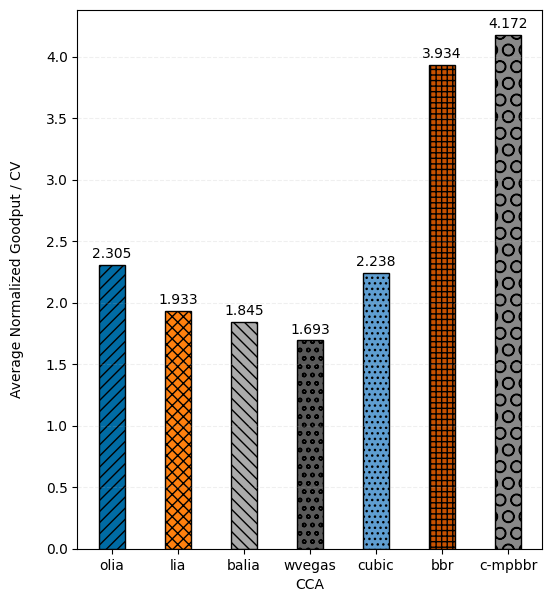

olia 0.256
lia 0.3
balia 0.309
wvegas 0.319
cubic 0.286
bbr 0.183
c-mpbbr 0.151


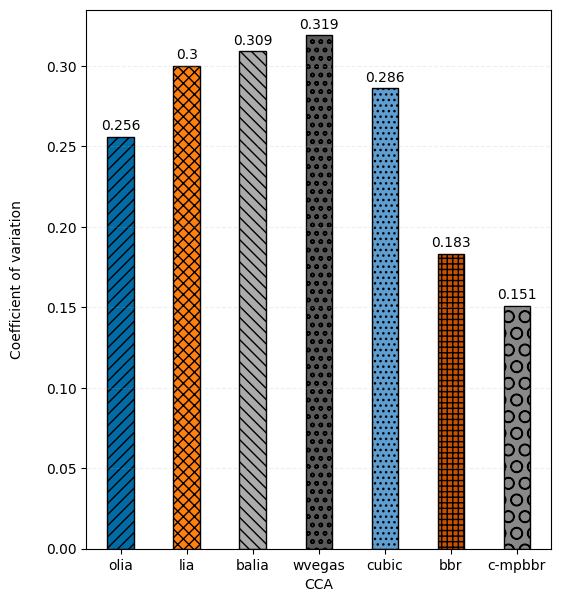

In [ ]:
# For each CCA, calculate the coefficient of variation (CV): σ/μ, where 'σ' is the normalized goodput's standard deviation. -> (lowest is better -- no huge variations around the mean)
# This metric provides a measurement of the extent of variability in relation to the mean of the population.

# CCA overall score metric (score) = avg_score / CV  
# -> this metric considers not only the absolute normalized goodput value, but also the performance stability across the scenario families.
# (basing the overall score merely on the CV would incur unclear results, since a CCA with a much lower but more stable performance would achieve higher CV; however, this does not mean it is performing best)

# %matplotlib widget
# import ipympl
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os
import seaborn as sns
import matplotlib as mpl
from cycler import cycler


def return_file_w_pattern(dir, pattern):
    found = False
    for file in os.listdir(dir):
        filename = os.path.join(dir, file)
        if os.path.isfile(filename) and pattern in str(filename):
            found = True
            break
    if found:
        return file
    else:
        print("File with requested pattern not found!\n")
        exit()


def create_csv_file(dirpath, id, target):
    csv_name = f"{id}_{target}.csv"
    csv_full_name = os.path.join(dirpath, csv_name)
    with open(csv_full_name, 'w', encoding='utf-8') as f:
        if target == 'goodput':
            f.write("scenario_family,subscen_id,avg_aggr_gp\n")
        elif target == 'score':
            f.write("scenario_family,score\n")
        elif target == 'avg_score':
            f.write("CCA,avg_score,avg_score_std,cv,score\n")
    return csv_full_name


def calculate_cc_overall_score(cc_list, assess_dir, cca_avg_score_full_path):
    for cc in cc_list:
        i = 0
        cca_sc_sum = 0.0
        cca_avg_score = 0.0
        cca_avg_score_std = 0.0
        score_parent_dir = os.path.join(assess_dir, cc)
        cca_score_f_pattern = str(cc + '_score')
        cca_score_file = return_file_w_pattern(score_parent_dir, cca_score_f_pattern)
        cca_score_file_path = os.path.join(score_parent_dir, cca_score_file)
        
        # calculate cca_avg_score
        with open(cca_score_file_path, 'r', encoding='utf-8') as cca_sc_f:
            lines = cca_sc_f.readlines()[1:]  # skip header line
            for line in lines:
                cca_sc_sample = float(str(line).split(",")[1].lstrip())
                cca_sc_sum += float(str("%.2f" % float(cca_sc_sample)))
                i+=1
        if(i!=5):
            print("There is an error: the number of scenario scores should be five (5).\n")
            exit()
        cca_avg_score = float(str("%.2f" % float(cca_sc_sum / i)))
        
        # calculate cca_avg_score std (σ)
        cca_score_df = pd.read_csv(cca_score_file_path, skipinitialspace=True)
        cca_avg_score_std = float(str("%.3f" % float(cca_score_df['score'].std(ddof=0))))

        #calculate coefficient of variation of each CCA's normalized goodput score (σ/μ)
        cca_cv = float(str("%.3f" % float(cca_avg_score_std / cca_avg_score)))

        #calculate overall score = avg_score / cv  (given CV != 0)
        if(cca_cv != 0):
            cca_score = float(str("%.3f" % float(cca_avg_score / cca_cv)))
        else:
            print("CV is 0.\n")
            exit()
        with open(cca_avg_score_full_path, 'a', encoding='utf-8') as cca_avg_sc_f:
            cca_avg_sc_f.write("%s,%s,%s,%s,%s\n" %(cc, str(cca_avg_score), str(cca_avg_score_std), str(cca_cv), str(cca_score)))


# Paths
local_path = "/home/mininet/mininet/mininet_dd/full_suite/analysis/"  # VM-specific
remote_merge_path = "/home/ubuntu/code_backup/mininet_dd/full_suite/analysis/merge_results/"
images_path = os.path.join(local_path, 'images')

cc_list = ['olia', 'lia', 'balia', 'wvegas', 'cubic', 'bbr', 'c-mpbbr']
# cc_list = ['bbr']
sched_list = ['minRTT', 'BLEST', 'ECF', 'RR', 'LLHD']
scen_list = ['homogen', 'int_het', 'mild_het', 'mix_het', 'v_int_het']

# 'final_assessment' dir
assess_dir_name = 'final_assessment'
assess_filepath = os.path.join(local_path, assess_dir_name)

# For each CCA, calculate the average of the normalized goodput across all five (5) scenario families; append the results of all CCAs to a common .csv file
cca_avg_score_csv = create_csv_file(assess_filepath, 'CCA', 'avg_score')
calculate_cc_overall_score(cc_list, assess_filepath, cca_avg_score_csv)

# Draw histogram of cca_avg_score CV
cca_avg_score_csv_pattern = str('CCA_avg_score')
cca_avg_score_csv = return_file_w_pattern(assess_filepath, cca_avg_score_csv_pattern)
cca_avg_score_csv_path = os.path.join(assess_filepath, cca_avg_score_csv)
cca_avg_score_df = pd.read_csv(cca_avg_score_csv_path, skipinitialspace=True)
cca_list = list(cca_avg_score_df['CCA'])
cca_cv_list = list(cca_avg_score_df['cv'])
cca_cv_score_list = list(cca_avg_score_df['score'])

fig_horiz_dimen = 6
fig_vert_dimen = 7
title_font_size = 10
width = 0.4  # the width of the bars

# Hatching
hatches = ['///', 'xxx', '\\\\\\', 'oo', '...', '+++', 'O', 'x', 'o', '.', '*']
grays = ['#E5E5E5', '#BFBFBF', '#999999', '#737373', '#4D4D4D']


#--- overall_score = avg_score / CV ---#
fig, axs = plt.subplots(figsize=(fig_horiz_dimen, fig_vert_dimen))  # dpi=500

# Tableau palette - comment out to revert to legacy RGB
axs.set_prop_cycle(color=["#006ba4", "#ff800e", "#ababab", "#595959", "#5f9ed1", "#c85200", "#898989", "#a2c8ec", "#ffbc79", "#cfcfcf"])

cca_avg_score_df = cca_avg_score_df.reset_index()  # make sure indexes pair with number of rows
for index, row in cca_avg_score_df.iterrows():
    print(row['CCA'], row['score'])
    bar_cont = axs.bar(row['CCA'], row['score'], width, label=None, hatch=hatches[index], edgecolor='black')
    axs.bar_label(bar_cont, padding=3)

axs.set_ylabel('Average Normalized Goodput / CV\n', multialignment='center', fontsize='medium')
# axs.set_title('CCA overall score', fontsize=title_font_size)   # comment out
axs.grid(axis='y', linestyle='--', alpha=0.2)  # remove?
axs.grid(axis='x', visible=False)
# axs.set_ylim(bottom=0, top=1.2)  # remove?
axs.set_xlabel('CCA')
# fig.suptitle('CCA overall score')

# # Use seaborn palette and apply it to matplotlib
# palette = sns.color_palette("Set2", 8)
# plt.rcParams['axes.prop_cycle'] = plt.cycler(color=palette)

# axs.legend(cc_list, ncols=2)  # loc='lower left'
# ax.legend(loc='upper left', ncols=3)

# Save figure
fig_name = 'CCA_overall_score_NG_CV.jpg'
fig_name_full_path = os.path.join(images_path, fig_name)
plt.savefig(fig_name_full_path, dpi=600)
plt.show()


# --- CV plot ---#
fig, axs = plt.subplots(figsize=(fig_horiz_dimen, fig_vert_dimen))  # dpi=500

# Tableau palette - comment out to revert to legacy RGB
axs.set_prop_cycle(color=["#006ba4", "#ff800e", "#ababab", "#595959", "#5f9ed1", "#c85200", "#898989", "#a2c8ec", "#ffbc79", "#cfcfcf"])

cca_avg_score_df = cca_avg_score_df.reset_index()  # make sure indexes pair with number of rows
for index, row in cca_avg_score_df.iterrows():
    print(row['CCA'], row['cv'])
    bar_cont = axs.bar(row['CCA'], row['cv'], width, label=None, hatch=hatches[index], edgecolor='black')
    axs.bar_label(bar_cont, padding=3)

axs.set_ylabel('Coefficient of variation\n', multialignment='center', fontsize='medium')
# axs.set_title('CCA CV', fontsize=title_font_size)   # comment out
axs.grid(axis='y', linestyle='--', alpha=0.2)  # remove?
axs.grid(axis='x', visible=False)
axs.set_xlabel('CCA')
# Save figure
fig_name = 'CCA_CV.jpg'
fig_name_full_path = os.path.join(images_path, fig_name)
plt.savefig(fig_name_full_path, dpi=600)
plt.show()



Schedulers' assessment

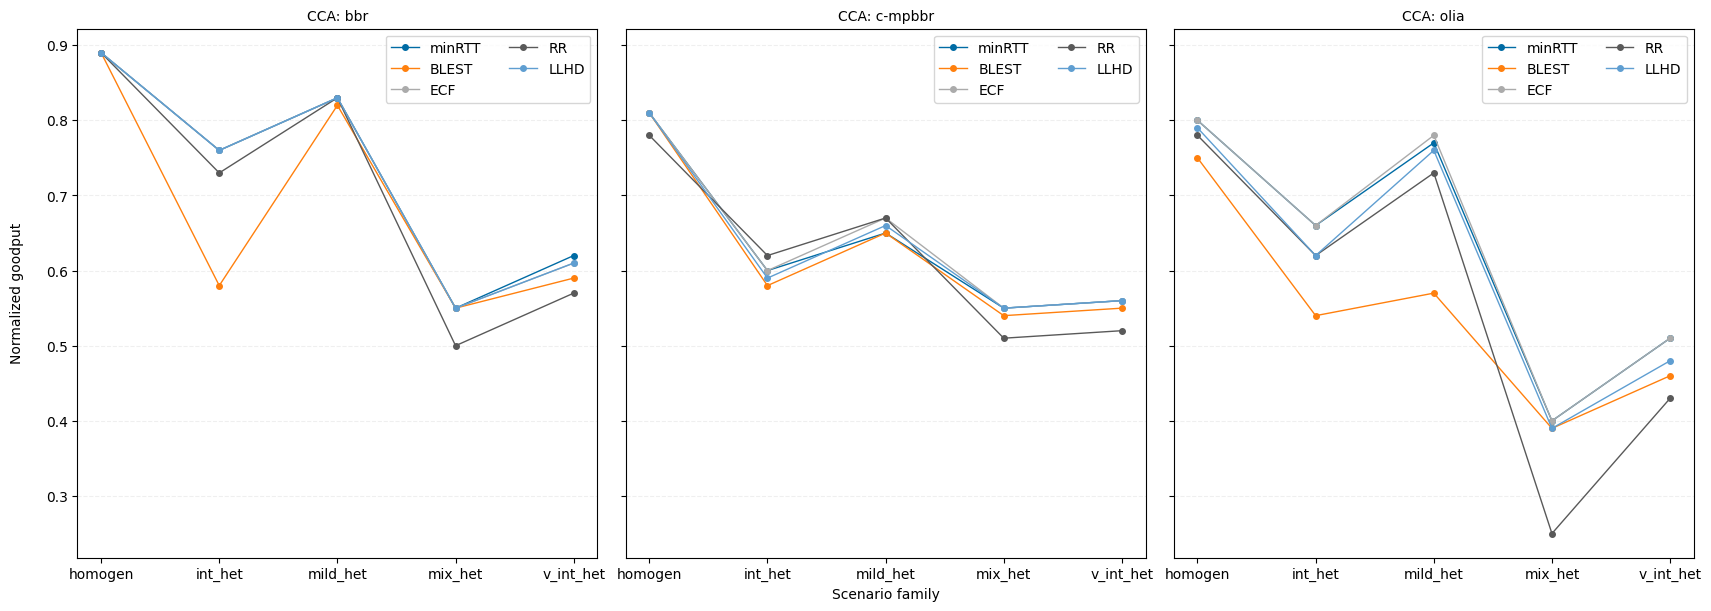

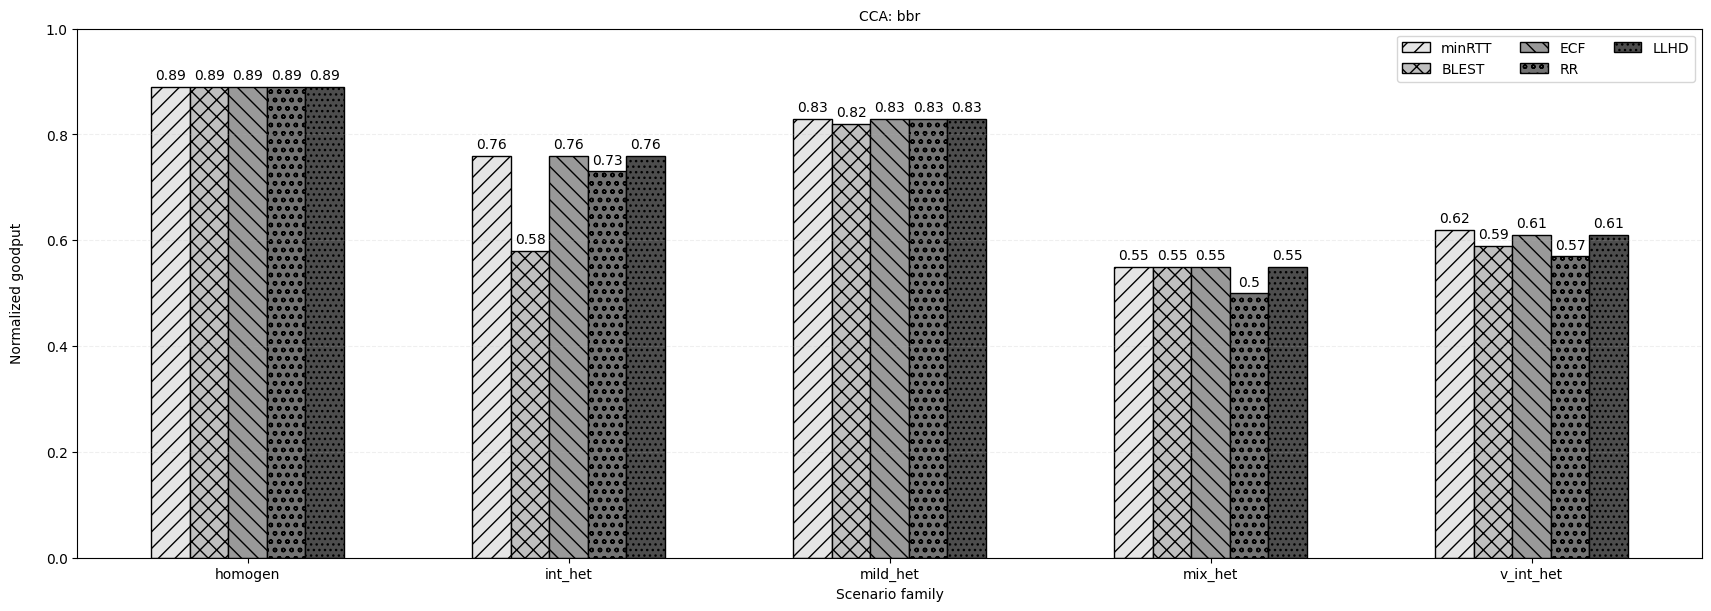

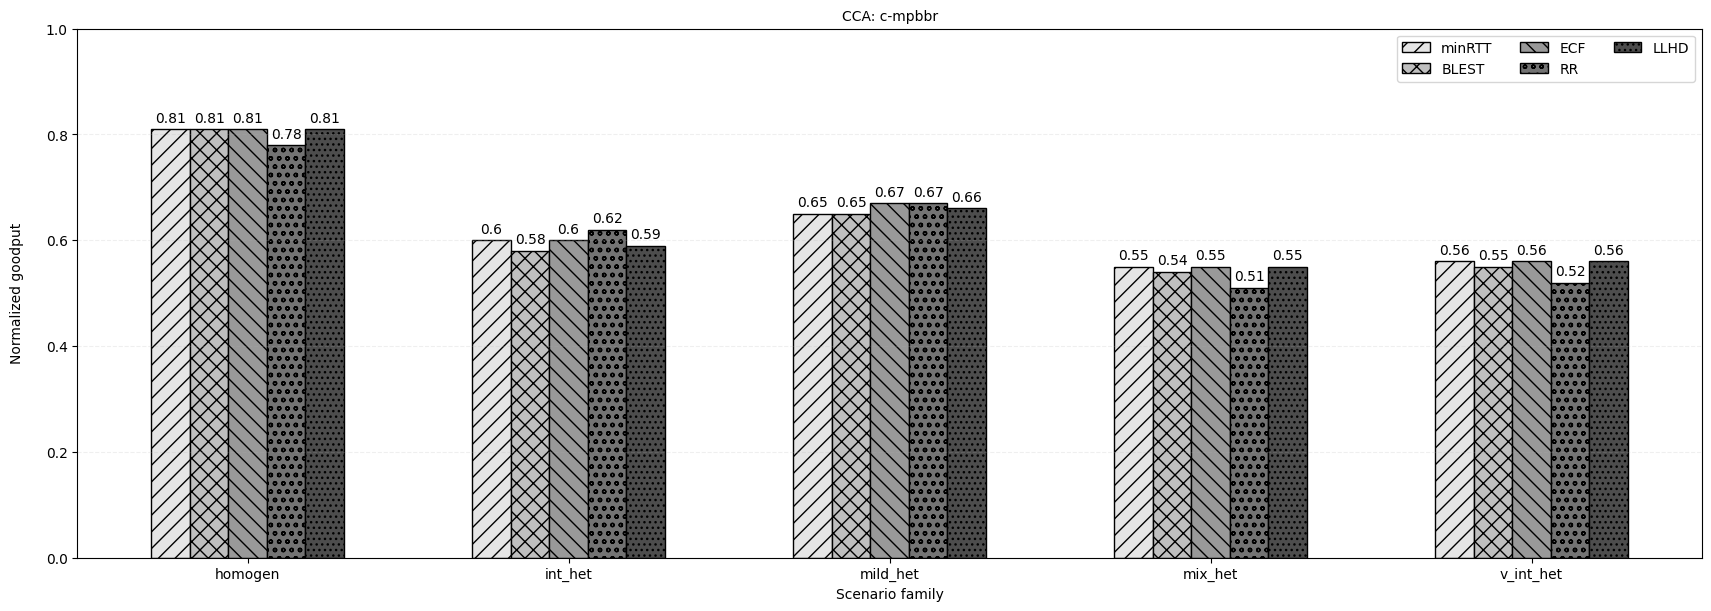

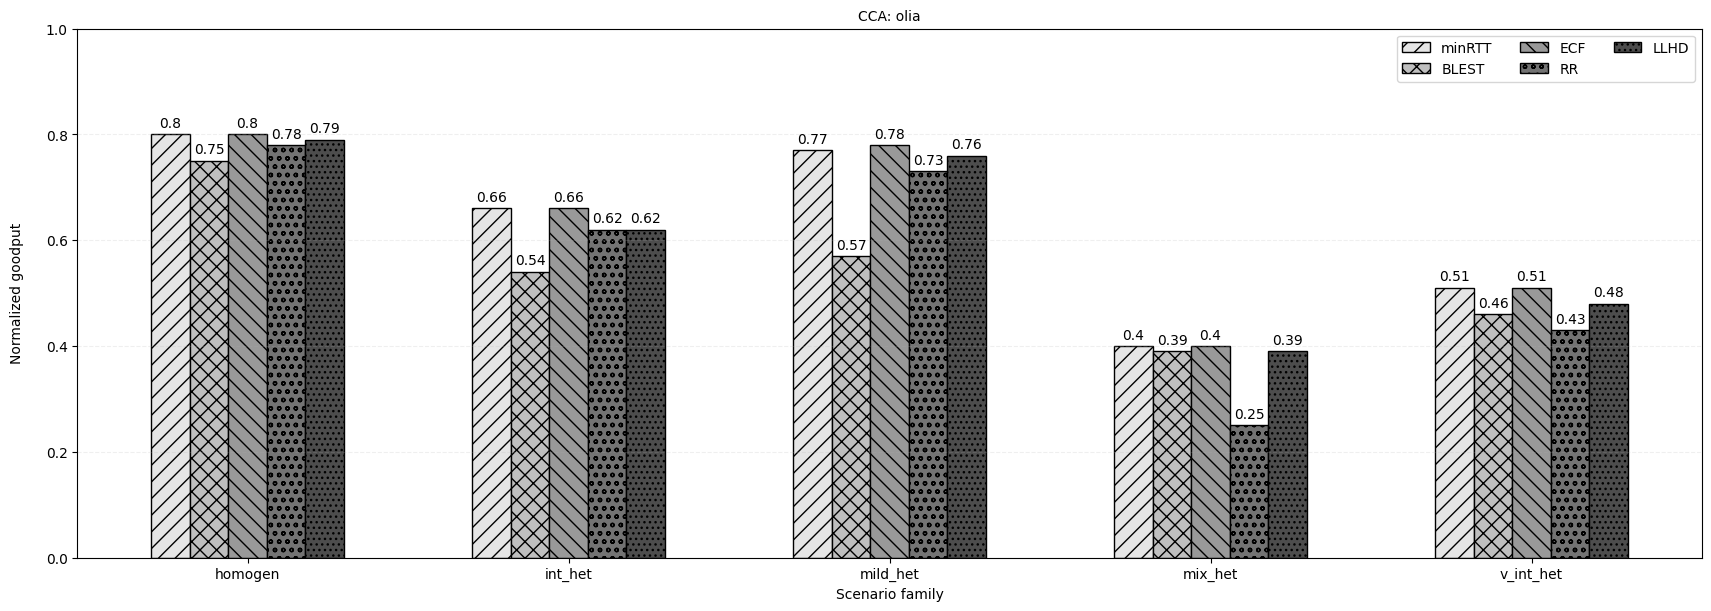

In [ ]:
# For each CCA, showcase how each scheduler performs (in terms of goodput) across each scenario family.
# Then, calculate a heatmap with the avg_score (normalized_goodput = achieved_goodput / theoritical_max), in each schenario family, each time in combination with one of the three (3) best CCAs.   


# CCA overall assessment metric (score) = avg_score / CV
# (basing the overall score merely on the CV would incur unclear results, since a CCA with lower but mofre stable performance would achieve higher CV; however, this does not mean it is performing best)

# %matplotlib widget
# import ipympl
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os
from cycler import cycler
import numpy as np

def return_file_w_pattern(dir, pattern):
    found = False
    for file in os.listdir(dir):
        filename = os.path.join(dir, file)
        if os.path.isfile(filename) and pattern in str(filename):
            found = True
            break
    if found:
        return file
    else:
        print("File with requested pattern not found!\n")
        exit()


# Paths
local_path = "/home/mininet/mininet/mininet_dd/full_suite/analysis/"  # VM-specific
remote_merge_path = "/home/ubuntu/code_backup/mininet_dd/full_suite/analysis/merge_results/"
images_path = os.path.join(local_path, 'images')

# cc_list = ['olia', 'lia', 'balia', 'wvegas', 'cubic', 'bbr', 'c-mpbbr']
best_cc_list = ['bbr', 'c-mpbbr', 'olia']
# cc_list = ['bbr']
sched_list = ['minRTT', 'BLEST', 'ECF', 'RR', 'LLHD']
scen_list = ['homogen', 'int_het', 'mild_het', 'mix_het', 'v_int_het']

# 'final_assessment' dir
assess_dir_name = 'final_assessment'
assess_filepath = os.path.join(local_path, assess_dir_name)

fig_horiz_dimen = 17
fig_vert_dimen = 6
title_font_size = 10


fig, axs = plt.subplots(1, len(best_cc_list), figsize=(fig_horiz_dimen, fig_vert_dimen), sharex=True, sharey=True, layout='constrained')  # sharey='row' // gridspec_kw={'height_ratios': [4, 7]}  // layout='constrained' // dpi=500
axs[0].set_ylabel('Normalized goodput\n', multialignment='center', fontsize='medium')
axs[1].set_xlabel('Scenario family')
for iter, cc in enumerate(best_cc_list):
    cc_filepath = os.path.join(assess_filepath, cc)
    # Tableau palette - comment out to revert to legacy RGB
    axs[iter].set_prop_cycle(color=["#006ba4", "#ff800e", "#ababab", "#595959", "#5f9ed1", "#c85200", "#898989", "#a2c8ec", "#ffbc79", "#cfcfcf"])
    # axs.set_ylabel('Scheduler normalized goodput\n', multialignment='center', fontsize='medium')
    axs[iter].set_title(f'CCA: {cc}', fontsize=title_font_size)   # comment out
    axs[iter].grid(axis='y', linestyle='--', alpha=0.2)  # remove?
    axs[iter].grid(axis='x', visible=False)
    # axs.set_ylim(bottom=0, top=1.2)  # remove?
    # axs[iter].set_xlabel('Scenario family')
    for sched in sched_list:
        sched_score_csv_pattern = str(sched + '_' + 'score')
        sched_score_csv = return_file_w_pattern(cc_filepath, sched_score_csv_pattern)
        sched_score_csv_path = os.path.join(cc_filepath, sched_score_csv)
        sched_score_df = pd.read_csv(sched_score_csv_path, skipinitialspace=True)
        sched_scen_fam_list = list(sched_score_df['scenario_family'])
        sched_score_list = list(sched_score_df['score'])
        # fig.suptitle(str(subscen))
        axs[iter].plot(sched_scen_fam_list, sched_score_list, marker='o', linestyle='solid', linewidth=1, markersize=4)
        axs[iter].legend(sched_list, ncols=2)  # loc='lower left'   
fig_name = 'Combined_sched_norm_gp_lineplot_all_CCAs.jpg'
fig_name_full_path = os.path.join(images_path, fig_name)
plt.savefig(fig_name_full_path, dpi=600)


## Hatching
hatches = ['//', 'xx', '\\\\', 'oo', '...', '+', 'x', 'o', 'O', '.', '*']
grays = ['#E5E5E5', '#BFBFBF', '#999999', '#737373', '#4D4D4D']
for iter, cc in enumerate(best_cc_list):
    fig, axs = plt.subplots(1, 1, figsize=(fig_horiz_dimen, fig_vert_dimen), sharex=True, sharey=True, layout='constrained')  # sharey='row' // gridspec_kw={'height_ratios': [4, 7]}  // layout='constrained' // dpi=500
    axs.set_ylabel('Normalized goodput\n', multialignment='center', fontsize='medium')
    axs.set_xlabel('Scenario family')
    # fig.suptitle(str(cc))
    x = np.arange(len(scen_list))  # the label locations
    width = 0.12  # the width of the bars
    multiplier = 0

    cc_filepath = os.path.join(assess_filepath, cc)
    # Tableau palette - comment out to revert to legacy RGB
    # axs.set_prop_cycle(color=["#006ba4", "#ff800e", "#ababab", "#595959", "#5f9ed1", "#c85200", "#898989", "#a2c8ec", "#ffbc79", "#cfcfcf"])
    axs.set_title(f'CCA: {cc}', fontsize=title_font_size)   # comment out
    axs.grid(axis='y', linestyle='--', alpha=0.2)  # remove?
    axs.grid(axis='x', visible=False)
    axs.set_ylim(bottom=0, top=1)
    # axs[iter].set_xlabel('Scenario family')
    for i, sched in enumerate(sched_list):
        sched_score_csv_pattern = str(sched + '_' + 'score')
        sched_score_csv = return_file_w_pattern(cc_filepath, sched_score_csv_pattern)
        sched_score_csv_path = os.path.join(cc_filepath, sched_score_csv)
        sched_score_df = pd.read_csv(sched_score_csv_path, skipinitialspace=True)
        sched_scen_fam_list = list(sched_score_df['scenario_family'])
        sched_score_list = list(sched_score_df['score'])
        # Matplotlib specific
        offset = width * multiplier
        bar_cont = axs.bar(x + offset, sched_score_list, width, label=sched, hatch=hatches[i], edgecolor='black', color=grays[i])
        axs.bar_label(bar_cont, padding=3)
        multiplier += 1
    axs.set_xticks(x + 2*width, scen_list)
    axs.legend(loc='upper right', ncols=3)
    # Save figure
    fig_name = f'Sched_norm_gp_barchart_CCA_{cc}.jpg'
    fig_name_full_path = os.path.join(images_path, fig_name)
    plt.savefig(fig_name_full_path, dpi=600)


plt.show()


Schedulers' comparison (heatmap)

[[0.89 0.76 0.83 0.55 0.62]
 [0.89 0.58 0.82 0.55 0.59]
 [0.89 0.76 0.83 0.55 0.61]
 [0.89 0.73 0.83 0.5  0.57]
 [0.89 0.76 0.83 0.55 0.61]]


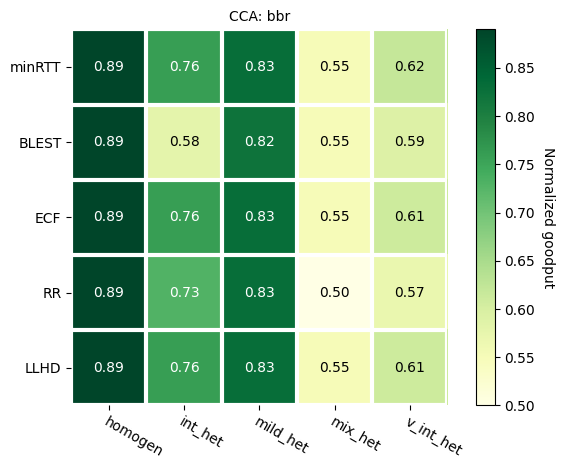

[[0.81 0.6  0.65 0.55 0.56]
 [0.81 0.58 0.65 0.54 0.55]
 [0.81 0.6  0.67 0.55 0.56]
 [0.78 0.62 0.67 0.51 0.52]
 [0.81 0.59 0.66 0.55 0.56]]


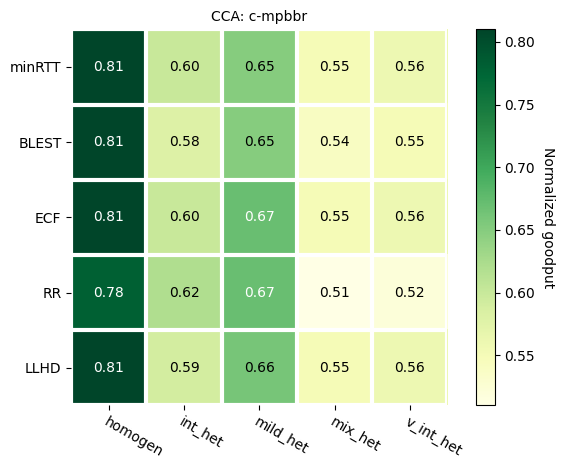

[[0.8  0.66 0.77 0.4  0.51]
 [0.75 0.54 0.57 0.39 0.46]
 [0.8  0.66 0.78 0.4  0.51]
 [0.78 0.62 0.73 0.25 0.43]
 [0.79 0.62 0.76 0.39 0.48]]


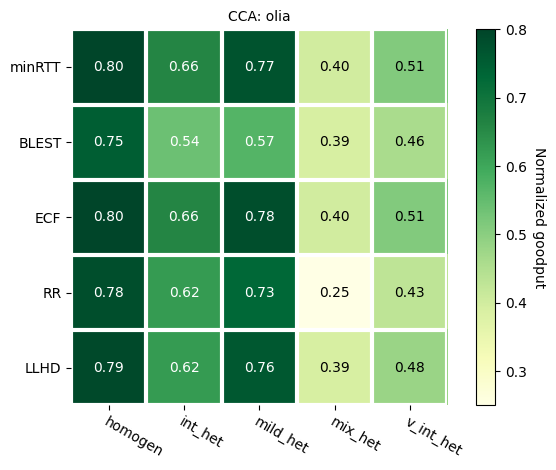

In [ ]:
# For each one of the top-3 CCAs, create a heatmap with the normalized goodput value of each scheduler, in each scenario family.

# %matplotlib widget
# import ipympl
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import matplotlib
import os
import numpy as np
import seaborn as sns
from cycler import cycler


def return_file_w_pattern(dir, pattern):
    found = False
    for file in os.listdir(dir):
        filename = os.path.join(dir, file)
        if os.path.isfile(filename) and pattern in str(filename):
            found = True
            break
    if found:
        return file
    else:
        print("File with requested pattern not found!\n")
        exit()


def heatmap(data, row_labels, col_labels, ax=None,
            cbar_kw=None, cbarlabel="", **kwargs):
    """
    Create a heatmap from a numpy array and two lists of labels.

    Parameters
    ----------
    data
        A 2D numpy array of shape (M, N).
    row_labels
        A list or array of length M with the labels for the rows.
    col_labels
        A list or array of length N with the labels for the columns.
    ax
        A `matplotlib.axes.Axes` instance to which the heatmap is plotted.  If
        not provided, use current Axes or create a new one.  Optional.
    cbar_kw
        A dictionary with arguments to `matplotlib.Figure.colorbar`.  Optional.
    cbarlabel
        The label for the colorbar.  Optional.
    **kwargs
        All other arguments are forwarded to `imshow`.
    """

    if ax is None:
        ax = plt.gca()

    if cbar_kw is None:
        cbar_kw = {}

    # Plot the heatmap
    im = ax.imshow(data, **kwargs)

    # Create colorbar
    cbar = ax.figure.colorbar(im, ax=ax, **cbar_kw)
    cbar.ax.set_ylabel(cbarlabel, rotation=-90, va="bottom")

    # Show all ticks and label them with the respective list entries.
    ax.set_xticks(range(data.shape[1]), labels=col_labels,
                  rotation=-30, ha="left", rotation_mode="anchor")
    ax.set_yticks(range(data.shape[0]), labels=row_labels)

    # Let the horizontal axes labeling appear on top.
    ax.tick_params(top=False, bottom=True,
                   labeltop=False, labelbottom=True)

    # Turn spines off and create white grid.
    ax.spines[:].set_visible(False)

    ax.set_xticks(np.arange(data.shape[1]+1)-.5, minor=True)
    ax.set_yticks(np.arange(data.shape[0]+1)-.5, minor=True)
    ax.grid(which="minor", color="w", linestyle='-', linewidth=3)
    ax.tick_params(which="minor", bottom=False, left=False)

    return im, cbar


def annotate_heatmap(im, data=None, valfmt="{x:.2f}",
                     textcolors=("black", "white"),
                     threshold=None, **textkw):
    """
    A function to annotate a heatmap.

    Parameters
    ----------
    im
        The AxesImage to be labeled.
    data
        Data used to annotate.  If None, the image's data is used.  Optional.
    valfmt
        The format of the annotations inside the heatmap.  This should either
        use the string format method, e.g. "$ {x:.2f}", or be a
        `matplotlib.ticker.Formatter`.  Optional.
    textcolors
        A pair of colors.  The first is used for values below a threshold,
        the second for those above.  Optional.
    threshold
        Value in data units according to which the colors from textcolors are
        applied.  If None (the default) uses the middle of the colormap as
        separation.  Optional.
    **kwargs
        All other arguments are forwarded to each call to `text` used to create
        the text labels.
    """

    if not isinstance(data, (list, np.ndarray)):
        data = im.get_array()

    # Normalize the threshold to the images color range.
    if threshold is not None:
        threshold = im.norm(threshold)
    else:
        threshold = im.norm(data.max())/2.

    # Set default alignment to center, but allow it to be
    # overwritten by textkw.
    kw = dict(horizontalalignment="center",
              verticalalignment="center")
    kw.update(textkw)

    # Get the formatter in case a string is supplied
    if isinstance(valfmt, str):
        valfmt = matplotlib.ticker.StrMethodFormatter(valfmt)

    # Loop over the data and create a `Text` for each "pixel".
    # Change the text's color depending on the data.
    texts = []
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            kw.update(color=textcolors[int(im.norm(data[i, j]) > threshold)])
            text = im.axes.text(j, i, valfmt(data[i, j], None), **kw)
            texts.append(text)

    return texts


# Paths
local_path = "/home/mininet/mininet/mininet_dd/full_suite/analysis/"  # VM-specific
remote_merge_path = "/home/ubuntu/code_backup/mininet_dd/full_suite/analysis/merge_results/"
images_path = os.path.join(local_path, 'images')

# cc_list = ['olia', 'lia', 'balia', 'wvegas', 'cubic', 'bbr', 'c-mpbbr']
best_cc_list = ['bbr', 'c-mpbbr', 'olia']
# best_cc_list = ['bbr']
sched_list = ['minRTT', 'BLEST', 'ECF', 'RR', 'LLHD']
scen_list = ['homogen', 'int_het', 'mild_het', 'mix_het', 'v_int_het']

# 'final_assessment' dir
assess_dir_name = 'final_assessment'
assess_filepath = os.path.join(local_path, assess_dir_name)


# Uncomment for single figure plotting (3-sublots / single figure)
# fig, axs = plt.subplots(1, len(best_cc_list), figsize=(fig_horiz_dimen, fig_vert_dimen), sharex=False, sharey=False, layout='constrained')  # layout='tight'

for iter, cc in enumerate(best_cc_list):
    dfs = []
    score_list = []
    np_arr = np.array([])
    cc_filepath = os.path.join(assess_filepath, cc)
    for sched in sched_list:
        sched_score_csv_pattern = str(sched + '_' + 'score')
        sched_score_csv = return_file_w_pattern(cc_filepath, sched_score_csv_pattern)
        sched_score_csv_path = os.path.join(cc_filepath, sched_score_csv)
        sched_score_df = pd.read_csv(sched_score_csv_path, skipinitialspace=True)
        dfs.append(sched_score_df)
        score_list.append(list(sched_score_df['score']))
    data = np.array(score_list)
    print(data)
    # Uncomment for single figure plotting (3-sublots / single figure)
    # im, cbar = heatmap(data, sched_list, scen_list, ax=axs[iter], cmap="YlGn", cbarlabel="Normalized goodput")
    # texts = annotate_heatmap(im, valfmt="{x:.2f}")

    # Separate heatmap figures per CCA
    fig, ax = plt.subplots()  # dpi=500
    # sns.color_palette("flare", as_cmap=True)
    # sns.heatmap(data=data, linecolor="white", linewidths=1, annot=True, fmt=".2f")
    im, cbar = heatmap(data, sched_list, scen_list, ax=ax, cmap="YlGn", cbarlabel="Normalized goodput")  # cmap="YlGn", cmap="magma", "viridis", "flare", "inferno", ..
    texts = annotate_heatmap(im, valfmt="{x:.2f}")
    ax.set_title(f'CCA: {cc}', fontsize=title_font_size)
    fig.tight_layout()
     # Save figure
    fig_name = f'sched_heatmap_CCA_{cc}.jpg'
    fig_name_full_path = os.path.join(images_path, fig_name)
    plt.savefig(fig_name_full_path, dpi=600)
    plt.show()
    plt.close(fig)


Schedulers' goodput assessment (ECCDF) - Empirical Complementary Cumulative Distribution Function: P(X > x)

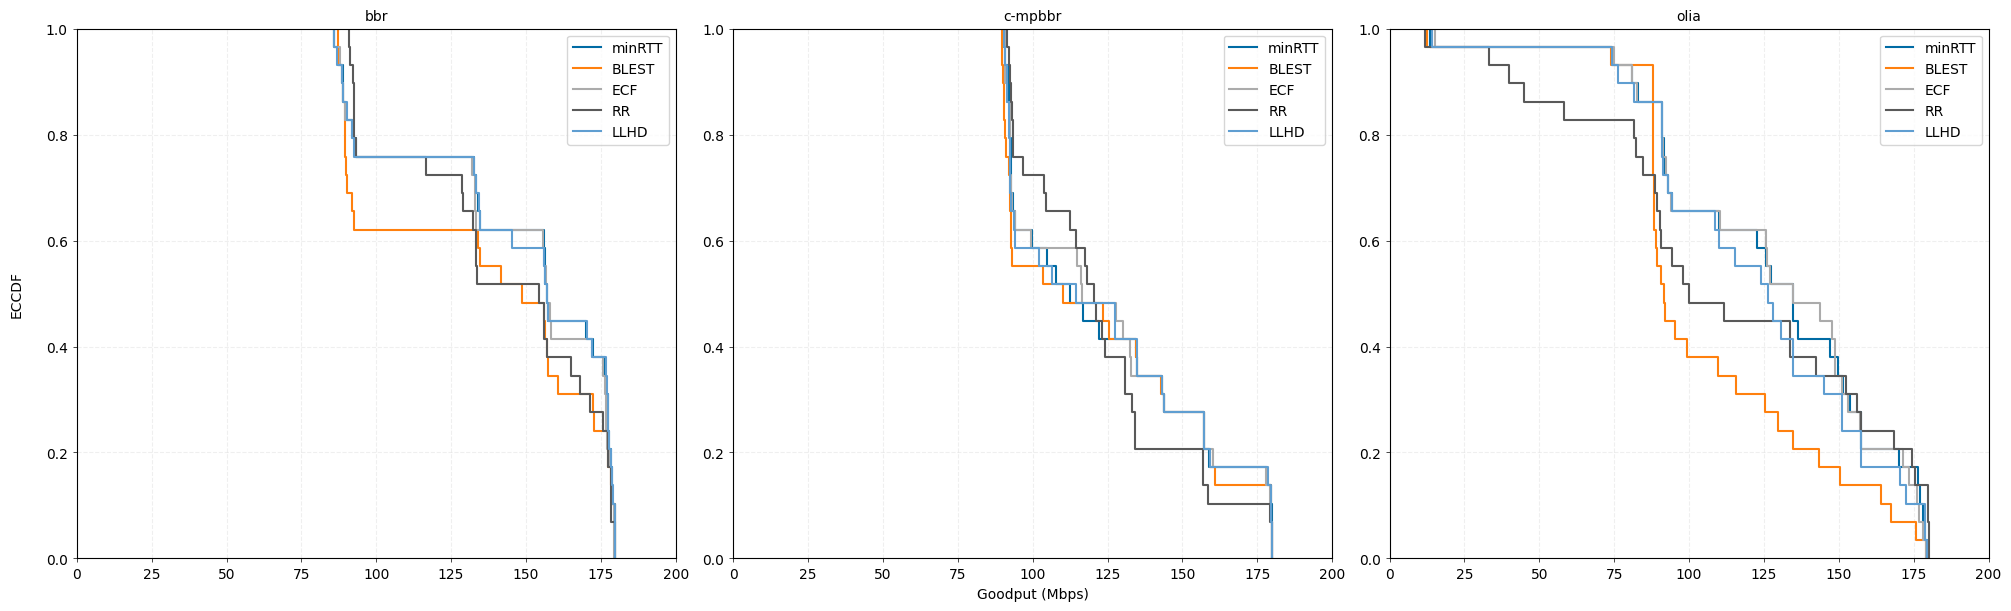

In [ ]:
# For each one of the top-3 CCAs (BBR, C-MPBBR, OLIA), draw the ECCDF depicting each scheduler's probability to achieve above a specific level of goodput (considers goodput input from all scenario families and sub-scenarios).

# %matplotlib widget
# import ipympl
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import matplotlib
import os
import numpy as np
import seaborn as sns
from cycler import cycler


def return_file_w_pattern(dir, pattern):
    found = False
    for file in os.listdir(dir):
        filename = os.path.join(dir, file)
        if os.path.isfile(filename) and pattern in str(filename):
            found = True
            break
    if found:
        return file
    else:
        print("File with requested pattern not found!\n")
        exit()


# Paths
local_path = "/home/mininet/mininet/mininet_dd/full_suite/analysis/"  # VM-specific
remote_merge_path = "/home/ubuntu/code_backup/mininet_dd/full_suite/analysis/merge_results/"
images_path = os.path.join(local_path, 'images')

# cc_list = ['olia', 'lia', 'balia', 'wvegas', 'cubic', 'bbr', 'c-mpbbr']
best_cc_list = ['bbr', 'c-mpbbr', 'olia']
# best_cc_list = ['bbr']
sched_list = ['minRTT', 'BLEST', 'ECF', 'RR', 'LLHD']
scen_list = ['homogen', 'int_het', 'mild_het', 'mix_het', 'v_int_het']

# 'final_assessment' dir
assess_dir_name = 'final_assessment'
assess_filepath = os.path.join(local_path, assess_dir_name)


# Plotting
fig_horiz_dimen = 20
fig_vert_dimen = 6
title_font_size = 10

fig, axs = plt.subplots(1, len(best_cc_list), figsize=(fig_horiz_dimen, fig_vert_dimen), sharex=True, sharey=False, layout='constrained')  # sharey='row' // gridspec_kw={'height_ratios': [4, 7]}  // layout='constrained' // dpi=500
# axs[0].set_ylabel('Probability of occurrence\n', multialignment='center', fontsize='medium')
axs[0].set_ylabel('ECCDF\n', multialignment='center', fontsize='medium')
axs[1].set_xlabel('Goodput (Mbps)')

for iter, cc in enumerate(best_cc_list):
    cc_filepath = os.path.join(assess_filepath, cc)
    # Plotting config
    axs[iter].set_prop_cycle(color=["#006ba4", "#ff800e", "#ababab", "#595959", "#5f9ed1", "#c85200", "#898989", "#a2c8ec", "#ffbc79", "#cfcfcf"])
    axs[iter].set_title(f'{cc}', fontsize=title_font_size)
    axs[iter].grid(True, linestyle='--', alpha=0.2)
    
    for sched in sched_list:
        sched_gp_csv_pattern = str(sched + '_' + 'goodput')
        sched_gp_csv = return_file_w_pattern(cc_filepath, sched_gp_csv_pattern)
        sched_gp_csv_path = os.path.join(cc_filepath, sched_gp_csv)
        sched_gp_df = pd.read_csv(sched_gp_csv_path, skipinitialspace=True)
        
        # Complementary cumulative distributions.
        axs[iter].ecdf(sched_gp_df['avg_aggr_gp'], complementary=True, label=f"{sched}")
        axs[iter].legend()
        # axs[iter].label_outer()
        axs[iter].autoscale(enable=True)
        axs[iter].tick_params(axis='both', which='major', length=3, width=.5)
        axs[iter].set_xbound(0, 200)

# fig.suptitle("ECCDF")
# Save figure
fig_name = 'Combined_sched_goodput_ECCDF_best_CCAs.jpg'
fig_name_full_path = os.path.join(images_path, fig_name)
plt.savefig(fig_name_full_path, dpi=600)
plt.show()
plt.close(fig)


Per Packet Delay - Calculation

In [ ]:
# Calculate the per packet delay (max Ethernet Frame size = 1514 B) for each scheduler under each one of the: BBR, C-MPBBR, OLIA CCAs.
# It is an average estimation of the RTT, which does not consider instantaneous RTT fluctuations -- SRTT measurements are explicitly presented via SRTT boxplots within Goodput figures 
# 
# pps (packets per second) = #total_Bytes / (1514 * 30)
# per_packet_delay (s) = 1 / pps
# per_packet_delay (ms) = (1 / pps) * 1000



# %matplotlib widget
# import ipympl
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os
from subprocess import run, Popen, PIPE
from subprocess import CompletedProcess
# import seaborn as sns
import numpy as np
import textwrap
from shutil import move, rmtree
import pwd, grp



def return_file_w_pattern(dir, pattern):
    found = False
    for file in os.listdir(dir):
        filename = os.path.join(dir, file)
        if os.path.isfile(filename) and pattern in str(filename):
            found = True
            break
    if found:
        return file
    else:
        print("File with requested pattern not found!\n")
        exit()


def create_csv_file(dirpath, id, target):
    csv_name = f"{id}_{target}.csv"
    csv_full_name = os.path.join(dirpath, csv_name)
    with open(csv_full_name, 'w', encoding='utf-8') as f:
        if target == 'goodput':
            f.write("scenario_family,subscen_id,avg_aggr_gp\n")
        elif target == 'score':
            f.write("scenario_family,score\n")
        elif target == 'pps':
            f.write("scenario_family,subscen_id,avg_bytes,pps,pdelay\n")
        elif target == 'avg_pdelay':
            f.write("scenario_family,avg_pdelay\n")
    return csv_full_name


''' Calculate average 'pps' and 'average packet delay' for each scheduler in each sub-scenario, across all five (5) identical iterations. 
    Append the results in the respective scheduler's '{sched}_pdelay.csv' file. '''
def calculate_average_pdelay(gp_file_full_path, scheduler):
    with open(gp_file_full_path, 'r', encoding='utf-8') as f:
        lines = f.readlines()
        i = 0
        bytes_sum = 0
        avg_bytes = 0
        pps = 0
        pdelay = 0.0
        for line in lines:
            if str(line).startswith(scheduler) is True:
                bytes_sample = int(str(line).split(",")[8].lstrip())    # !: in python3 64-bit architectures' integer size is constrained by the available memory -- in case of issues, loop over i, and if i==5, calculate the summation of avged_samples
                bytes_sum += bytes_sample
                i+=1
        if i == 5:
            avg_bytes = int(bytes_sum / 5)
            pps = int(avg_bytes / (1514 * 30))  # 1514 Bytes per packet -- 30s traffic duration
            pdelay = float(str("%.3f" % (1000 / float(pps))))  # pdelay (ms) = (1/pps) * 1000 ms
            # print(f"Avg_bytes={str(avg_bytes)},  PPS={str(pps)},  pdelay={str(pdelay)}")
        else:
            print(f"Less than five goodput entries included in the original merged .csv file for scheduler {scheduler}.")
            exit()
    return str(avg_bytes), str(pps), str(pdelay)


def append_avg_pdelay(csv_full_path, scenario_family, subscenario_id, avg_bytes, pps, pdelay):
    with open(csv_full_path, 'a', encoding='utf-8') as f:
        f.write("%s,%s,%s,%s,%s\n" %(scenario_family, subscenario_id, avg_bytes, pps, pdelay))


''' Average packet delay per-scheduler per-scenario-family (per-CCA). '''
def calculate_sched_pdelay_score(pdelay_file_full_path, pdelay_score_file_path, id):
    with open(pdelay_file_full_path, 'r', encoding='utf-8') as pdelay_f:
        lines = pdelay_f.readlines()
        i = 0
        pdelay_sum = 0.0
        pdelay_score = 0.0
        for line in lines:
            if str(line).startswith(id) is True:
                pdelay_sample = float(str(line).split(",")[4].lstrip())
                pdelay_sum += float(str("%.3f" % float(pdelay_sample)))
                i+=1
        if ((id == 'homogen' or id == 'mix_het') and (i!=4)) or ((id == 'int_het' or id == 'mild_het' or id == 'v_int_het') and (i!=7)):
            # print(f"Subscenario: {id}, i = {i}, score_fp = {score_file_path}")
            print(f"Subscenario entries do not match the expected number.")
            exit()
        pdelay_score = float(str("%.3f" % float(pdelay_sum / i)))
    with open(pdelay_score_file_path, 'a', encoding='utf-8') as sc_f:
        sc_f.write("%s,%s\n" %(id, str(pdelay_score)))


# Paths
local_path = "/home/mininet/mininet/mininet_dd/full_suite/analysis/"  # VM-specific
remote_merge_path = "/home/ubuntu/code_backup/mininet_dd/full_suite/analysis/merge_results/"

# cc_list = ['olia', 'lia', 'balia', 'wvegas', 'cubic', 'bbr', 'c-mpbbr']
# cc_list = ['bbr']
best_cc_list = ['bbr', 'c-mpbbr', 'olia']
sched_list = ['minRTT', 'BLEST', 'ECF', 'RR', 'LLHD']
scen_list = ['homogen', 'int_het', 'mild_het', 'mix_het', 'v_int_het']

# 'final_assessment' dir
assess_dir_name = 'final_assessment'
assess_filepath = os.path.join(local_path, assess_dir_name)


# Calculate the average delay of each packet for each scheduler in each sub-scenario (e.g., e1, e2, ..) over the 5 identical runs --> append the results to a per-scheduler .csv file under each CCA assessments' directory
for cc in best_cc_list:
    assess_cc_dir_path = os.path.join(assess_filepath, cc)
    cc_filepath = os.path.join(local_path, cc)
    for sched in sched_list:
        sched_pps_csv_name = create_csv_file(assess_cc_dir_path, sched, 'pps') # create an assessments' .csv file per scheduler within parent cc dir
        sched_pps_csv_full_name = os.path.join(assess_cc_dir_path, sched_pps_csv_name)  # scheduler .csv full path
        for outer_scenario in sorted(os.listdir(cc_filepath)):  # i.e. homogen, mild, ..
            outer_scenario_path = os.path.join(cc_filepath, outer_scenario)
            for scenario in sorted(os.listdir(outer_scenario_path)):  # i.e. scenario = 'e1_xyz'
                scenario_path = os.path.join(outer_scenario_path, scenario)
                gp_file = return_file_w_pattern(scenario_path, 'goodput')
                gp_file_full_path = os.path.join(scenario_path, gp_file)
                avg_bytes, pps, pdelay = calculate_average_pdelay(gp_file_full_path, sched)
                append_avg_pdelay(sched_pps_csv_full_name, outer_scenario, scenario, avg_bytes, pps, pdelay)


# Calculate the average packet delay (avg_pdelay) (named also avg_pdelay 'score') for each Scheduler in each scenario family, for the three best CCAs: BBR, C-MPBBR, OLIA 
# avg_pdelay = Sum_pdelay (aggregate pdelay of all subscenarios of single scenario_family) / (#_subscenarios)
for cc in best_cc_list:
    assess_cc_dir_path = os.path.join(assess_filepath, cc)
    # calculate each scheduler's avg_pdelay in each scenario family - single avg_pdelay score file per scheduler (per CCA)
    for sched in sched_list:
        sched_pdelay_score_csv_name = create_csv_file(assess_cc_dir_path, sched, 'avg_pdelay') # create a score .csv file per scheduler within parent cc dir
        sched_pdelay_score_csv_full_path = os.path.join(assess_cc_dir_path, sched_pdelay_score_csv_name)
        sched_pdelay_f_pattern = str(sched) + str("_pps")
        sched_pdelay_file = return_file_w_pattern(assess_cc_dir_path, sched_pdelay_f_pattern)
        sched_pdelay_file_full_path = os.path.join(assess_cc_dir_path, sched_pdelay_file)
        for scen in scen_list:
            calculate_sched_pdelay_score(sched_pdelay_file_full_path, sched_pdelay_score_csv_full_path, scen)



Per Packet Delay - Plotting

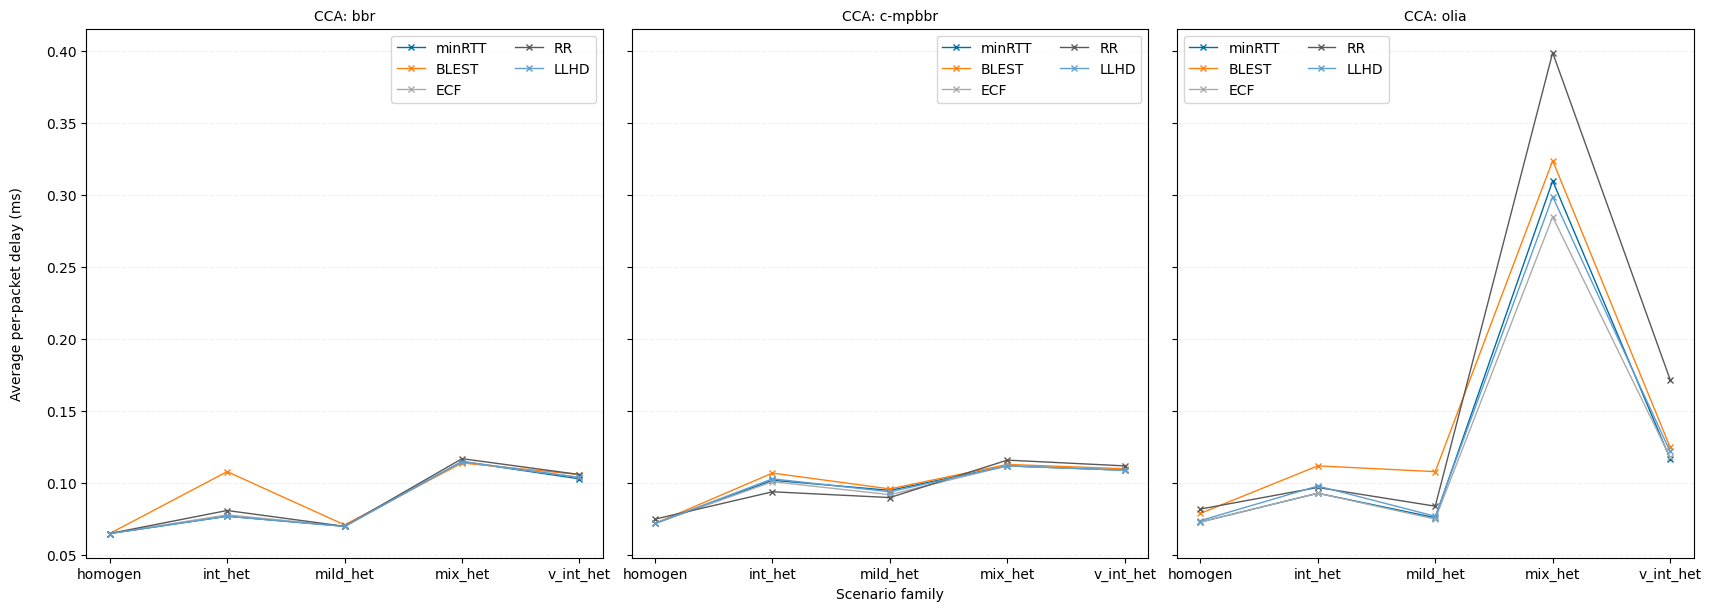

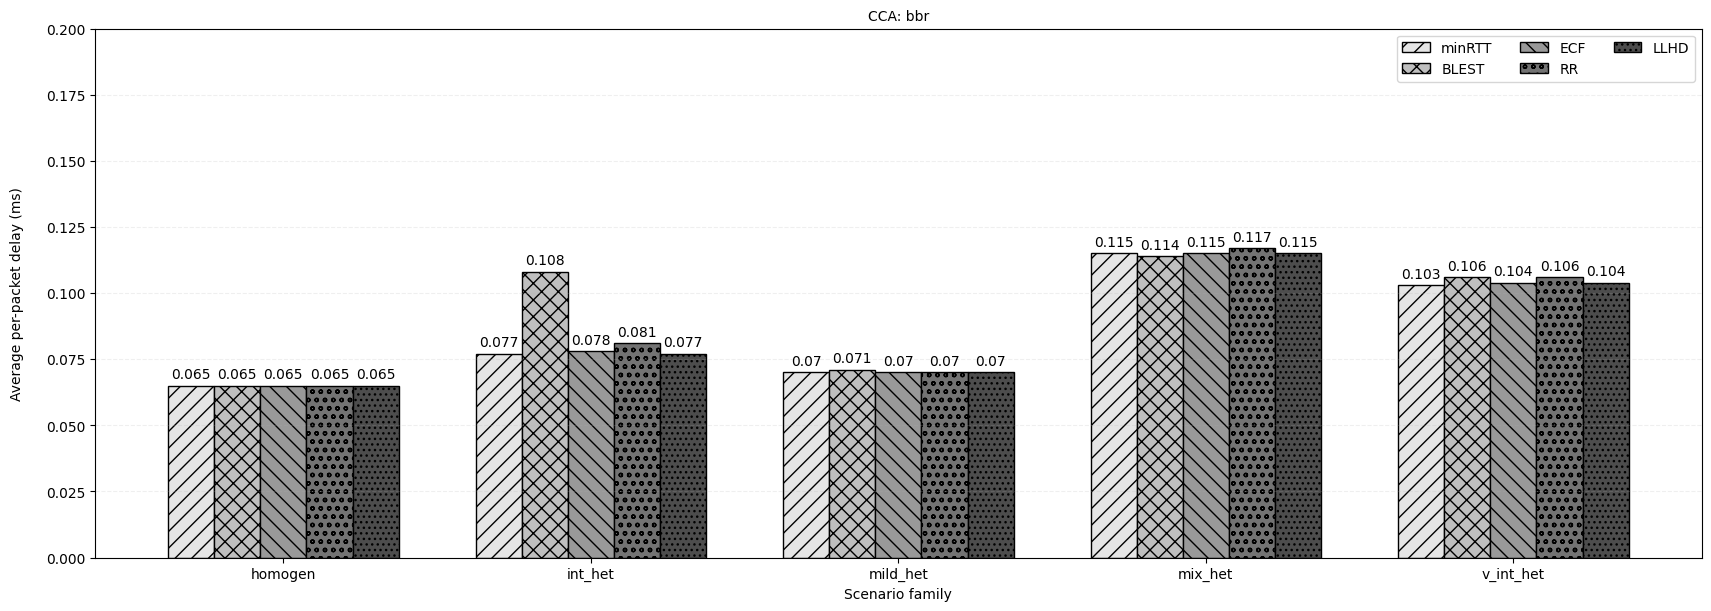

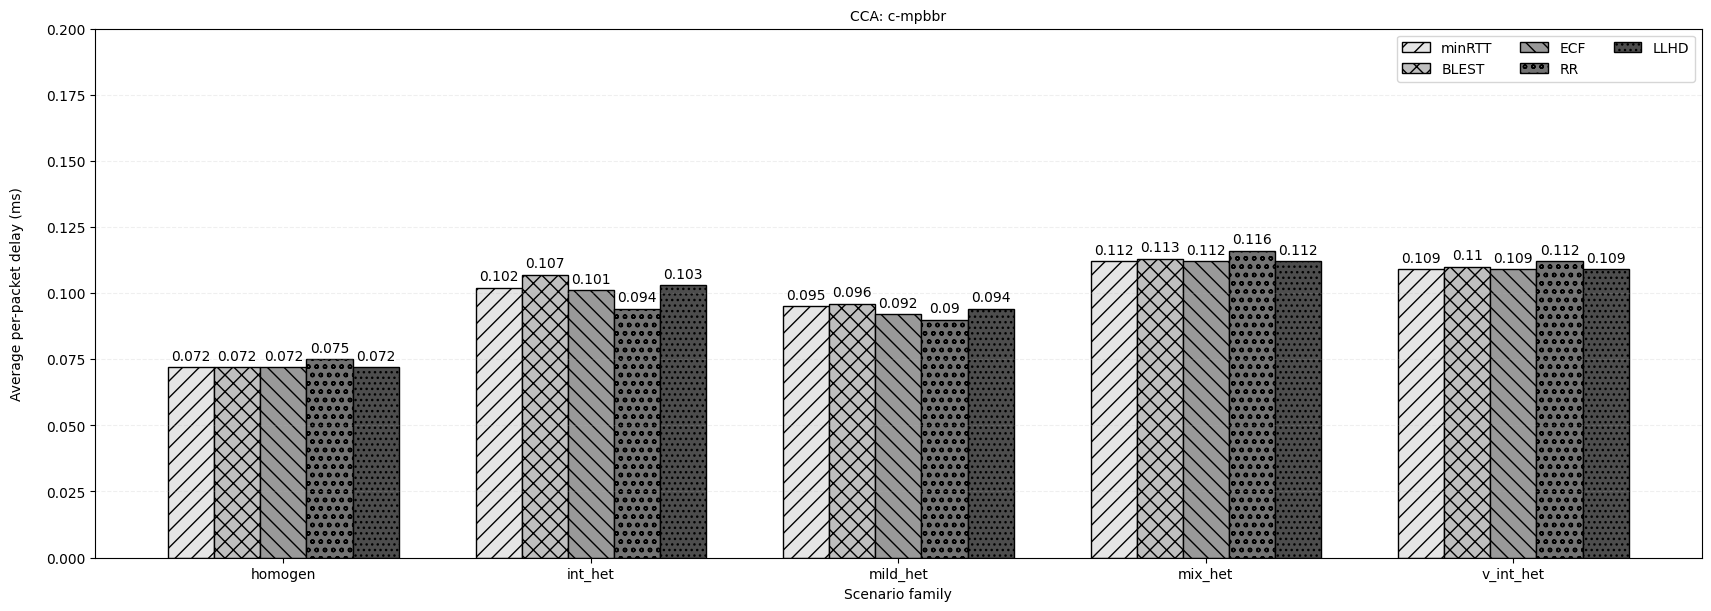

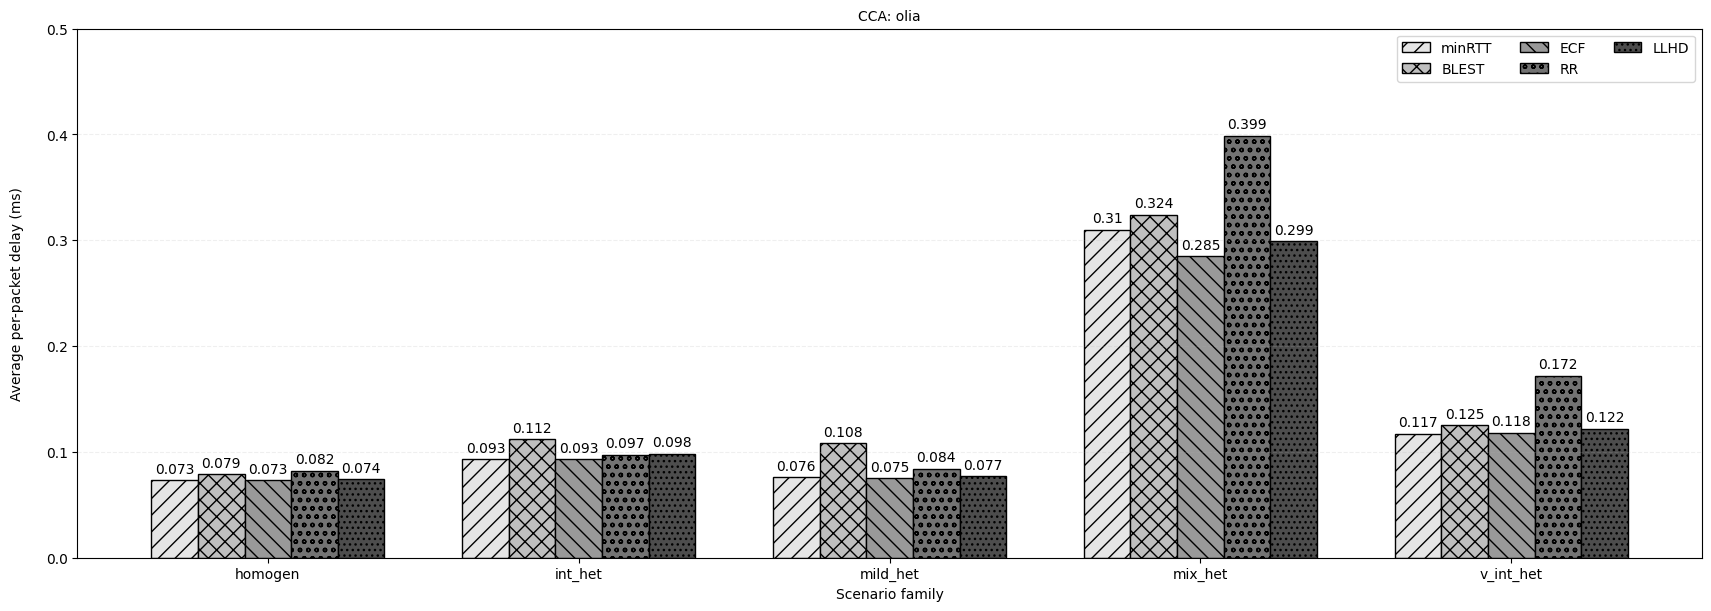

In [ ]:
# For each of the three best (in terms of goodput) CCAs, showcase how each scheduler performs (in terms of avg. packet delay) across each scenario family.


# %matplotlib widget
# import ipympl
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os
from cycler import cycler
import numpy as np


def return_file_w_pattern(dir, pattern):
    found = False
    for file in os.listdir(dir):
        filename = os.path.join(dir, file)
        if os.path.isfile(filename) and pattern in str(filename):
            found = True
            break
    if found:
        return file
    else:
        print("File with requested pattern not found!\n")
        exit()


# Paths
local_path = "/home/mininet/mininet/mininet_dd/full_suite/analysis/"  # VM-specific
remote_merge_path = "/home/ubuntu/code_backup/mininet_dd/full_suite/analysis/merge_results/"
images_path = os.path.join(local_path, 'images')

# cc_list = ['olia', 'lia', 'balia', 'wvegas', 'cubic', 'bbr', 'c-mpbbr']
best_cc_list = ['bbr', 'c-mpbbr', 'olia']
# cc_list = ['bbr']
sched_list = ['minRTT', 'BLEST', 'ECF', 'RR', 'LLHD']
scen_list = ['homogen', 'int_het', 'mild_het', 'mix_het', 'v_int_het']

# 'final_assessment' dir
assess_dir_name = 'final_assessment'
assess_filepath = os.path.join(local_path, assess_dir_name)

fig_horiz_dimen = 17
fig_vert_dimen = 6
title_font_size = 10


fig, axs = plt.subplots(1, len(best_cc_list), figsize=(fig_horiz_dimen, fig_vert_dimen), sharex=True, sharey=True, layout='constrained')  # sharey='row' // gridspec_kw={'height_ratios': [4, 7]}  // layout='constrained' // dpi=500
axs[0].set_ylabel('Average per-packet delay (ms)\n', multialignment='center', fontsize='medium')
axs[1].set_xlabel('Scenario family')
for iter, cc in enumerate(best_cc_list):
    cc_filepath = os.path.join(assess_filepath, cc)
    # Tableau palette - comment out to revert to legacy RGB
    axs[iter].set_prop_cycle(color=["#006ba4", "#ff800e", "#ababab", "#595959", "#5f9ed1", "#c85200", "#898989", "#a2c8ec", "#ffbc79", "#cfcfcf"])
    # axs.set_ylabel('Scheduler avg. per-packet delay (ms)\n', multialignment='center', fontsize='medium')
    axs[iter].set_title(f'CCA: {cc}', fontsize=title_font_size)   # comment out
    axs[iter].grid(axis='y', linestyle='--', alpha=0.2)  # remove?
    axs[iter].grid(axis='x', visible=False)
    # axs.set_ylim(bottom=0, top=1.2)  # remove?
    # axs[iter].set_xlabel('Scenario family')
    for sched in sched_list:
        sched_pdelay_score_csv_pattern = str(sched + '_avg_pdelay')
        sched_pdelay_score_csv = return_file_w_pattern(cc_filepath, sched_pdelay_score_csv_pattern)
        sched_pdelay_score_csv_path = os.path.join(cc_filepath, sched_pdelay_score_csv)
        sched_pdelay_score_df = pd.read_csv(sched_pdelay_score_csv_path, skipinitialspace=True)
        sched_pdelay_score_fam_list = list(sched_pdelay_score_df['scenario_family'])
        sched_pdelay_score_list = list(sched_pdelay_score_df['avg_pdelay'])
        # fig.suptitle(str(subscen))
        axs[iter].plot(sched_pdelay_score_fam_list, sched_pdelay_score_list, marker='x', linestyle='solid', linewidth=1, markersize=4)
        axs[iter].legend(sched_list, ncols=2)  # loc='lower left'    
# Save figure
fig_name = 'Combined_sched_ppd_lineplot_best_CCAs.jpg'
fig_name_full_path = os.path.join(images_path, fig_name)
plt.savefig(fig_name_full_path, dpi=600)
plt.show()
plt.close(fig)


## Hatching
hatches = ['//', 'xx', '\\\\', 'oo', '...', '+', 'x', 'o', 'O', '.', '*']
grays = ['#E5E5E5', '#BFBFBF', '#999999', '#737373', '#4D4D4D']
for iter, cc in enumerate(best_cc_list):
    fig, axs = plt.subplots(1, 1, figsize=(fig_horiz_dimen, fig_vert_dimen), sharex=True, sharey=True, layout='constrained')  # sharey='row' // gridspec_kw={'height_ratios': [4, 7]}  // layout='constrained' // dpi=500
    axs.set_ylabel('Average per-packet delay (ms)\n', multialignment='center', fontsize='medium')
    axs.set_xlabel('Scenario family')
    # fig.suptitle(str(cc))
    x = np.arange(len(scen_list))  # the label locations
    width = 0.15  # the width of the bars
    multiplier = 0

    cc_filepath = os.path.join(assess_filepath, cc)
    # Tableau palette - comment out to revert to legacy RGB
    # axs.set_prop_cycle(color=["#006ba4", "#ff800e", "#ababab", "#595959", "#5f9ed1", "#c85200", "#898989", "#a2c8ec", "#ffbc79", "#cfcfcf"])
    axs.set_title(f'CCA: {cc}', fontsize=title_font_size)   # comment out
    axs.grid(axis='y', linestyle='--', alpha=0.2)  # remove?
    axs.grid(axis='x', visible=False)
    # custom y-axis top limit per CC
    if (cc == 'bbr' or cc == 'c-mpbbr'):
        toplim = 0.2
    if (cc == 'olia'):
        toplim = 0.5
    # axs.set_ylim(bottom=0, top=0.5)
    axs.set_ylim(bottom=0, top=toplim)

    for i, sched in enumerate(sched_list):
        sched_pdelay_score_csv_pattern = str(sched + '_avg_pdelay')
        sched_pdelay_score_csv = return_file_w_pattern(cc_filepath, sched_pdelay_score_csv_pattern)
        sched_pdelay_score_csv_path = os.path.join(cc_filepath, sched_pdelay_score_csv)
        sched_pdelay_score_df = pd.read_csv(sched_pdelay_score_csv_path, skipinitialspace=True)
        sched_pdelay_score_fam_list = list(sched_pdelay_score_df['scenario_family'])
        sched_pdelay_score_list = list(sched_pdelay_score_df['avg_pdelay'])
        # Matplotlib specific
        offset = width * multiplier
        bar_cont = axs.bar(x + offset, sched_pdelay_score_list, width, label=sched, hatch=hatches[i], edgecolor='black', color=grays[i])
        axs.bar_label(bar_cont, padding=3)
        multiplier += 1
    # fig.suptitle(str(subscen))
    axs.set_xticks(x + 2*width, scen_list)
    axs.legend(loc='upper right', ncols=3)
    # Save figure
    fig_name = f'Sched_Avg_ppd_barchart_CCA_{cc}.jpg'
    fig_name_full_path = os.path.join(images_path, fig_name)
    plt.savefig(fig_name_full_path, dpi=600)
    plt.show()
    plt.close(fig)


Schedulers' average per-packet-delay assessment (ECDF) - Empirical Cumulative Distribution Function: P(X > x)

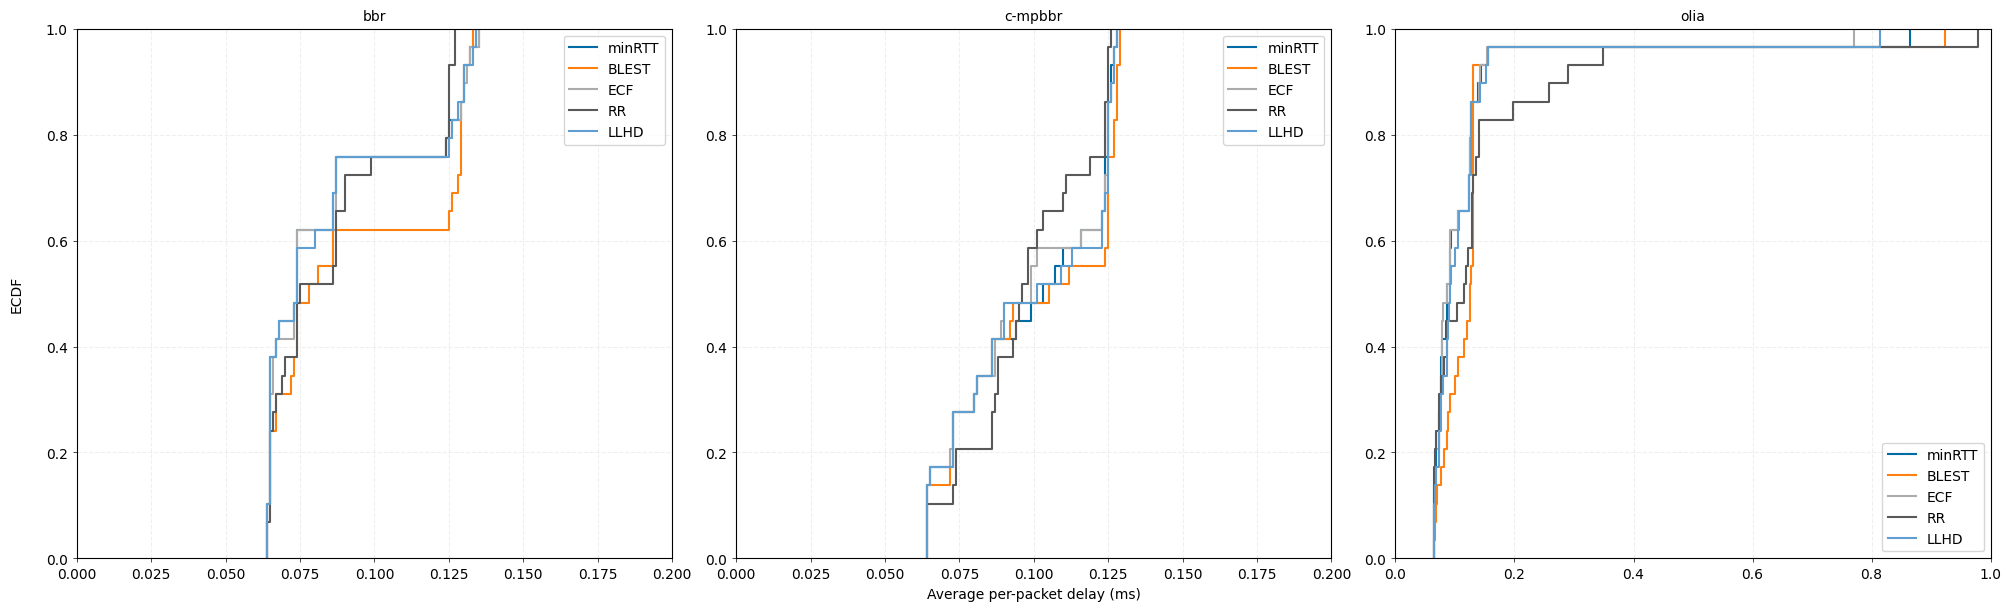

In [ ]:
# For each one of the top-3 CCAs (BBR, C-MPBBR, OLIA), draw the ECCDF depicting each scheduler's probability to achieve below a specific level of avg. per-packet delay
# (considers 'avg. per-packet delay' input from all scenario families and sub-scenarios: '{sched}_pps.csv').

# %matplotlib widget
# import ipympl
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import matplotlib
import os
import numpy as np
import seaborn as sns
from cycler import cycler


def return_file_w_pattern(dir, pattern):
    found = False
    for file in os.listdir(dir):
        filename = os.path.join(dir, file)
        if os.path.isfile(filename) and pattern in str(filename):
            found = True
            break
    if found:
        return file
    else:
        print("File with requested pattern not found!\n")
        exit()


# Paths
local_path = "/home/mininet/mininet/mininet_dd/full_suite/analysis/"  # VM-specific
remote_merge_path = "/home/ubuntu/code_backup/mininet_dd/full_suite/analysis/merge_results/"
images_path = os.path.join(local_path, 'images')

# cc_list = ['olia', 'lia', 'balia', 'wvegas', 'cubic', 'bbr', 'c-mpbbr']
best_cc_list = ['bbr', 'c-mpbbr', 'olia']
# best_cc_list = ['bbr']
sched_list = ['minRTT', 'BLEST', 'ECF', 'RR', 'LLHD']
scen_list = ['homogen', 'int_het', 'mild_het', 'mix_het', 'v_int_het']

# 'final_assessment' dir
assess_dir_name = 'final_assessment'
assess_filepath = os.path.join(local_path, assess_dir_name)


# Plotting
fig_horiz_dimen = 20
fig_vert_dimen = 6
title_font_size = 10

fig, axs = plt.subplots(1, len(best_cc_list), figsize=(fig_horiz_dimen, fig_vert_dimen), sharex=False, sharey=False, layout='constrained')  # sharey='row' // gridspec_kw={'height_ratios': [4, 7]}  // layout='constrained' // dpi=500
# axs[0].set_ylabel('Probability of occurrence\n', multialignment='center', fontsize='medium')
axs[0].set_ylabel('ECDF\n', multialignment='center', fontsize='medium')
axs[1].set_xlabel('Average per-packet delay (ms)')

for iter, cc in enumerate(best_cc_list):
    cc_filepath = os.path.join(assess_filepath, cc)
    # Plotting config
    axs[iter].set_prop_cycle(color=["#006ba4", "#ff800e", "#ababab", "#595959", "#5f9ed1", "#c85200", "#898989", "#a2c8ec", "#ffbc79", "#cfcfcf"])
    axs[iter].set_title(f'{cc}', fontsize=title_font_size)
    axs[iter].grid(True, linestyle='--', alpha=0.2)
    
    for sched in sched_list:
        sched_pdelay_csv_pattern = str(sched + '_pps')
        sched_pdelay_csv = return_file_w_pattern(cc_filepath, sched_pdelay_csv_pattern)
        sched_pdelay_csv_path = os.path.join(cc_filepath, sched_pdelay_csv)
        sched_pdelay_df = pd.read_csv(sched_pdelay_csv_path, skipinitialspace=True)

        # Cumulative distributions
        axs[iter].ecdf(sched_pdelay_df['pdelay'], complementary=False, label=f"{sched}")
        axs[iter].legend()
        # axs[iter].label_outer()
        axs[iter].autoscale(enable=True)
        axs[iter].tick_params(axis='both', which='major', length=3, width=.5)
        if cc == 'olia':
            upper_bound = 1
        else:
            upper_bound = .2
        axs[iter].set_xbound(0, upper_bound)

# fig.suptitle("ECDF")
# Save figure
fig_name = 'Combined_sched_ppd_ECDF_best_CCAs.jpg'
fig_name_full_path = os.path.join(images_path, fig_name)
plt.savefig(fig_name_full_path, dpi=600)
plt.show()
plt.close(fig)
